# 06 — Ouabain bifurcation analysis (checklist 3.5 + 3.6)

One-parameter equilibrium and limit-cycle continuation for **ouabain** in the validated 7D Plant–Kim / Canavier model, plus ouabain under **complete TTX**.

- Direct continuation in the physical pump current $I_{\mathrm{ep}}$
- Biological continuation in the scaling parameter $\alpha_P$
- Complete-TTX slice: $g_I=0$ ($\alpha_I=0$) with freepar $\alpha_P$
- Solver for equilibria: PyDSTool `EP-C` (`ContClass`)
- Periodic orbits: PyDSTool `LC-C` via **AUTO** in the project Docker image (`curuy/math3888:latest`)
- Canonical ODEs: `src/plant_kim_model.py` (not modified)
- $\alpha_P$ scaling: `src/plant_kim_analysis.py` ($I_{\mathrm{ep}}=\alpha_P\, I_{\mathrm{ep}}^{(0)}$)

**Out of scope:** two-parameter continuation in $(\alpha_I,\alpha_P)$; full parallel 5D AUTO campaign (5D is sanity-check only).

**Environment:** run this notebook end-to-end inside Docker Jupyter (`docker compose up -d`, project mounted at `/notebooks`) so AUTO is available for `LC-C`. Do not modify the host `.venv` for AUTO.

**Model time unit:** Plant–Kim time constants are in **milliseconds (ms)**; AUTO period `_T` is therefore reported in **ms**.

**No forced bifurcation counts.** Detect and report whatever unique Hopfs / LPs appear.


## 1. Aim and biological interpretation

Ouabain is modelled as progressive inhibition of the electrogenic Na/K pump. Under the working hypothesis, reducing pump strength from the untreated state toward complete block should change bursting toward regular beating (Hypothesis 2 / checklist 3.5). Under complete TTX, further pump inhibition is expected to quench the slow wave toward a stable equilibrium (Hypothesis 3 / checklist 3.6).

This notebook separates:

1. **Mathematical** exploration of a bounded $I_{\mathrm{ep}}$ equilibrium skeleton (including non-physical values).
2. **Biological** ouabain path $\alpha_P\in[0,1]$, with $\alpha_P=1$ untreated and $\alpha_P=0$ complete pump block.
3. **Combined-drug** one-parameter slice $\alpha_I=0$, $\alpha_P:1\to 0$ (7D with $g_I=0$).

EP-C describes equilibria and local stability. LC-C describes periodic-orbit branches seeded from **unique** Hopf points only. A Hopf outside the biological interval does **not** by itself establish the bursting-to-beating or slow-wave-to-equilibrium transition. An equilibrium fold (LP) on $[0,1]$ is an important landmark but is **not** by itself a SNIC/HOM.


## 2. Imports and environment


In [1]:
import csv
import logging
import sys
import warnings
from contextlib import redirect_stderr, redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
# Suppress findfont / ticker chatter in HTML exports.
logging.getLogger("matplotlib").setLevel(logging.ERROR)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import matplotlib.pyplot as plt
import numpy as np
import PyDSTool as dst

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
# AUTO LC-C compiles artefacts into CWD; ensure CWD is importable (Jupyter usually is).
if str(Path.cwd().resolve()) not in sys.path:
    sys.path.insert(0, str(Path.cwd().resolve()))

from src.plant_kim_model import (
    BASELINE_PARS,
    DEFAULT_ALGPARAMS,
    STATE_VARS,
    build_vode_system,
)
from src.plant_kim_analysis import (
    G_I0,
    I_EP0,
    analyse_equilibrium,
    build_alpha_P_vode_system,
    pars_from_alpha,
    scan_equilibrium_voltages,
    scan_slice,
)

FIGDIR = REPO_ROOT / "outputs" / "figures" / "ouabain_bifurcation"
DATADIR = REPO_ROOT / "outputs" / "data" / "ouabain_bifurcation"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATADIR.mkdir(parents=True, exist_ok=True)

# Mathematical I_ep continuation window (~4.5 x |I_EP0| each side of zero).
IEP_LO, IEP_HI = -1.0, 1.0
# Report figures use this display window (not the full numerical travel).
IEP_PLOT_LO, IEP_PLOT_HI = -1.0, 1.0
# Biological image of alpha_P in [0,1]: I_ep in [I_EP0, 0] = [-0.22, 0].
IEP_BIO_LO, IEP_BIO_HI = float(I_EP0), 0.0
# alpha_P plot window: wide enough to show exterior H (~-2) and LP (~3.2).
AP_PLOT_LO, AP_PLOT_HI = -2.5, 3.5

# LC envelopes must NOT reuse equilibrium blue (C0). Contrasting family colours.
LC_FAMILY_COLORS = ["C3", "darkviolet", "darkorange", "C2"]


def lc_family_color(i):
    return LC_FAMILY_COLORS[int(i) % len(LC_FAMILY_COLORS)]


print("executable:", sys.executable)
print("version:", sys.version.split()[0])
print("PyDSTool:", getattr(dst, "__version__", "?"))
print("FIGDIR:", FIGDIR)
print("DATADIR:", DATADIR)
print("g_I0 =", G_I0, "I_ep0 =", I_EP0)
print("I_ep continuation window: [{}, {}]".format(IEP_LO, IEP_HI))
print("biological I_ep image: [{}, {}]".format(IEP_BIO_LO, IEP_BIO_HI))
print("alpha_P plot window: [{}, {}]".format(AP_PLOT_LO, AP_PLOT_HI))
print("I_ep report plot window: [{}, {}]".format(IEP_PLOT_LO, IEP_PLOT_HI))
print("DEFAULT_ALGPARAMS:", DEFAULT_ALGPARAMS)
print("TIME UNIT: model ODEs use milliseconds (ms); AUTO _T reported in ms.")


executable: /usr/local/bin/python
version: 3.9.25
PyDSTool: 1.19.5
FIGDIR: /notebooks/outputs/figures/ouabain_bifurcation
DATADIR: /notebooks/outputs/data/ouabain_bifurcation
g_I0 = 4.0 I_ep0 = -0.22
I_ep continuation window: [-1.0, 1.0]
biological I_ep image: [-0.22, 0.0]
alpha_P plot window: [-2.5, 3.5]
I_ep report plot window: [-1.0, 1.0]
DEFAULT_ALGPARAMS: {'rtol': 1e-06, 'atol': 1e-08, 'stiff': True, 'init_step': 0.1, 'max_step': 1.0}
TIME UNIT: model ODEs use milliseconds (ms); AUTO _T reported in ms.


## 3. Verification of the ouabain parameterisation

In the canonical voltage equation the electrogenic pump enters as an additive current $I_{\mathrm{ep}}$ (baseline negative / hyperpolarising).

Analysis-level ouabain scaling in `pars_from_alpha` / `build_alpha_P_vode_system` is

$$
I_{\mathrm{ep}}^{\mathrm{eff}} = \alpha_P\, I_{\mathrm{ep}}^{(0)},\qquad I_{\mathrm{ep}}^{(0)}=-0.22
$$

(μA). Equivalently $\alpha_P = I_{\mathrm{ep}}^{\mathrm{eff}} / I_{\mathrm{ep}}^{(0)}$.

Because $I_{\mathrm{ep}}^{(0)}<0$, **reducing pump magnitude toward zero** maps $\alpha_P:1\to 0$ onto $I_{\mathrm{ep}}: -0.22\to 0$ (algebraically $I_{\mathrm{ep}}$ increases toward zero). Prefer the language “pump magnitude reduced toward zero” over “increasing $I_{\mathrm{ep}}$”.

| $\alpha_P$ | Meaning | Effective $I_{\mathrm{ep}}$ |
|---|---|---|
| $1$ | untreated / control | $-0.22$ |
| $0$ | complete ouabain block | $0$ |
| $(0,1)$ | partial blockade | $\alpha_P\cdot(-0.22)$ |

The intended biological ouabain path is $\alpha_P\in[0,1]$, equivalently

$$
I_{\mathrm{ep}}\in\bigl[I_{\mathrm{ep}}^{(0)},\,0\bigr]=[-0.22,\,0].
$$

Values outside this interval may appear in mathematical continuation but are **not** ordinary ouabain doses.


In [2]:
assert abs(I_EP0 - float(BASELINE_PARS["I_ep"])) < 1e-15
assert abs(float(pars_from_alpha(1.0, 1.0)["I_ep"]) - I_EP0) < 1e-15
assert abs(float(pars_from_alpha(1.0, 0.0)["I_ep"]) - 0.0) < 1e-15
assert abs(float(pars_from_alpha(1.0, 0.5)["I_ep"]) - 0.5 * I_EP0) < 1e-15

ode_alpha_check = build_alpha_P_vode_system(alpha_P=1.0)
assert abs(float(ode_alpha_check.pars["I_ep"]) - I_EP0) < 1e-15
assert abs(float(ode_alpha_check.pars["alpha_P"]) - 1.0) < 1e-15
print("Parameterisation checks: PASS")
print("Mapping: I_ep_eff = alpha_P * I_EP0  with I_EP0 =", I_EP0)
print("Biological I_ep interval: [{}, {}]".format(IEP_BIO_LO, IEP_BIO_HI))


Parameterisation checks: PASS
Mapping: I_ep_eff = alpha_P * I_EP0  with I_EP0 = -0.22
Biological I_ep interval: [-0.22, 0.0]


## 4. Baseline / control equilibrium (continuation seed)


In [3]:
def state_from_eq_info(info):
    return {k: float(info[k]) for k in STATE_VARS}


pars_ctrl = pars_from_alpha(1.0, 1.0)
roots = scan_equilibrium_voltages(pars_ctrl)
print("Untreated current-balance roots:")
seed = None
for r in roots:
    info = analyse_equilibrium(r["V_star"], pars_ctrl, r["root_type"])
    print(
        f"  V*={info['V_star']:.6f} mV  {info['stability']}  "
        f"maxRe={info['max_real_part']:.6g}"
    )
    if abs(float(info["V_star"]) + 18.3) < 2.0:
        seed = info

if seed is None:
    raise RuntimeError("Could not locate untreated equilibrium near V*=-18.3 mV")

eq_ics = state_from_eq_info(seed)
print("\nContinuation seed (untreated):")
for k, v in eq_ics.items():
    print(f"  {k:4s} = {v:.6f}")
print(f"control I_ep = {pars_ctrl['I_ep']}, alpha_I = 1, alpha_P = 1")


Untreated current-balance roots:
  V*=-47.407304 mV  unstable  maxRe=0.000331503
  V*=-33.341159 mV  unstable  maxRe=0.0645438
  V*=-18.311553 mV  unstable  maxRe=0.0189524

Continuation seed (untreated):
  V    = -18.311553
  X_K  = 0.469303
  X_A  = 0.894266
  Y_A  = 0.000192
  X_P  = 1.000000
  X_I  = 0.603682
  Y_I  = 0.037033
control I_ep = -0.22, alpha_I = 1, alpha_P = 1


## 5. Helper functions for continuation bookkeeping

Special-point labels such as `H1`/`H2` are software ordering, not a physical ranking. Forward/backward EP-C *can* detect the same physical Hopf twice on long overlapping runs; helpers therefore keep both:

1. **raw** software-detected special points;
2. **unique** physical special points after coordinate deduplication.

Report labels for ouabain use location relative to the biological interval:

- $I_{\mathrm{ep}}$: `H_bio` / `LP_bio` if in $[-0.22,0]$, else `H_ext` / `LP_ext`
- $\alpha_P$: `H_bio` / `LP_bio` if in $[0,1]$, else `H_ext` / `LP_ext`

Do **not** assume a fixed number of Hopfs or LPs.


In [4]:
def collect_special_points(curve, kinds=("H", "LP", "LPC", "MX", "B")):
    # Raw PyDSTool special points (software labels).
    rows = []
    for kind in kinds:
        for i in range(1, 20):
            lab = f"{kind}{i}"
            pt = curve.getSpecialPoint(lab)
            if pt is None:
                break
            row = {"label": lab, "type": kind, "software_label": lab}
            for key in pt.coordnames:
                try:
                    row[key] = float(pt[key])
                except Exception:
                    pass
            for pkey in ("_T", "period", "_p"):
                if pkey in pt.coordnames:
                    row["period"] = float(pt[pkey])
            rows.append(row)
    return rows


def deduplicate_specials(rows, param_key, atol_param=1e-3, atol_V=1e-2):
    # Collapse same-type specials that agree in (param, V) within tolerance.
    unique = []
    for row in rows:
        if param_key not in row or "V" not in row:
            unique.append(dict(row))
            continue
        matched = None
        for u in unique:
            if u["type"] != row["type"]:
                continue
            if param_key not in u or "V" not in u:
                continue
            if abs(u[param_key] - row[param_key]) <= atol_param and abs(u["V"] - row["V"]) <= atol_V:
                matched = u
                break
        if matched is None:
            u = dict(row)
            u["raw_labels"] = [row.get("software_label", row.get("label"))]
            unique.append(u)
        else:
            matched["raw_labels"].append(row.get("software_label", row.get("label")))
    return unique


def _numbered_label(base, counts):
    counts[base] = counts.get(base, 0) + 1
    n = counts[base]
    return base if n == 1 else f"{base}{n}"


def assign_physical_labels_Iep(unique_rows, bio_lo=None, bio_hi=0.0):
    # Report labels by location in biological I_ep image [I_EP0, 0].
    if bio_lo is None:
        bio_lo = float(I_EP0)
    counts = {}
    out = []
    for r in unique_rows:
        if r["type"] not in ("H", "LP") or "I_ep" not in r:
            u = dict(r)
            u["report_label"] = r.get("label", r["type"])
            u["label"] = u["report_label"]
            out.append(u)
            continue
        u = dict(r)
        in_bio = (bio_lo - 1e-8) <= r["I_ep"] <= (bio_hi + 1e-8)
        if r["type"] == "H":
            base = "H_bio" if in_bio else "H_ext"
        else:
            base = "LP_bio" if in_bio else "LP_ext"
        u["report_label"] = _numbered_label(base, counts)
        u["label"] = u["report_label"]
        u["in_biological_Iep"] = bool(in_bio)
        out.append(u)
    return out


def assign_physical_labels_alphaP(unique_rows):
    counts = {}
    out = []
    for r in unique_rows:
        if r["type"] not in ("H", "LP") or "alpha_P" not in r:
            u = dict(r)
            u["report_label"] = r.get("label", r["type"])
            u["label"] = u["report_label"]
            out.append(u)
            continue
        u = dict(r)
        in_bio = (0.0 - 1e-8) <= r["alpha_P"] <= (1.0 + 1e-8)
        if r["type"] == "H":
            base = "H_bio" if in_bio else "H_ext"
        else:
            base = "LP_bio" if in_bio else "LP_ext"
        u["report_label"] = _numbered_label(base, counts)
        u["label"] = u["report_label"]
        u["in_biological_01"] = bool(in_bio)
        out.append(u)
    return out


def print_specials(curve, tag=""):
    print(f"Special points{tag}:")
    for kind in ("H", "LP", "LPC", "MX", "B", "SP"):
        for i in range(1, 40):
            lab = f"{kind}{i}"
            pt = curve.getSpecialPoint(lab)
            if pt is None:
                break
            extras = []
            for k in pt.coordnames:
                if k in ("I_ep", "alpha_P", "g_I", "alpha_I", "V", "_T"):
                    extras.append(f"{k}={float(pt[k]):.6g}")
            print(f"  {lab}: " + ", ".join(extras))


def force_spout_stop(curve):
    # PyDSTool SPOut creates SPoints with stop=False; enable stop on SP-* points.
    n = 0
    for key, bp in list(getattr(curve, "BifPoints", {}).items()):
        if str(key).startswith("SP"):
            try:
                bp.stop = True
                n += 1
            except Exception:
                pass
    print(f"Enabled stop on {n} SPOut point(s)")


def max_real_from_point_index(sol, idx):
    try:
        evals = sol.labels[idx]["EP"]["data"]["evals"]
        return float(np.max(np.real(evals)))
    except Exception:
        return float("nan")


def branch_stability_mask(sol, freepar):
    g = np.asarray(sol[freepar], dtype=float)
    V = np.asarray(sol["V"], dtype=float)
    stable = np.zeros(len(g), dtype=bool)
    known = False
    for i in range(len(g)):
        m = max_real_from_point_index(sol, i)
        if np.isfinite(m):
            stable[i] = m < -1e-8
            known = True
    return g, V, stable, known


def save_special_csv(path, rows, extra_keys=()):
    keys = ["label", "type"]
    for row in rows:
        for k in row:
            if k not in keys:
                keys.append(k)
    for k in extra_keys:
        if k not in keys:
            keys.append(k)
    out_rows = []
    for row in rows:
        rr = dict(row)
        for k, v in list(rr.items()):
            if isinstance(v, (list, tuple)):
                rr[k] = ";".join(str(x) for x in v)
        out_rows.append(rr)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys, extrasaction="ignore")
        w.writeheader()
        for row in out_rows:
            w.writerow(row)
    print("saved", path, "n=", len(out_rows))


def plot_epc_report(
    ax,
    sol,
    freepar,
    specials,
    title,
    xlabel,
    shade_interval=None,
    shade_label=None,
    vlines=None,
):
    g, V, stable, known = branch_stability_mask(sol, freepar)
    if known and np.any(stable) and np.any(~stable):
        for mask, style, label in (
            (stable, "-", "stable (max Re < 0)"),
            (~stable, "--", "unstable (max Re >= 0)"),
        ):
            gg = g.copy()
            VV = V.copy()
            gg[~mask] = np.nan
            VV[~mask] = np.nan
            ax.plot(gg, VV, style, color="C0", lw=1.8, label=label, zorder=4)
    else:
        ax.plot(g, V, "-", color="C0", lw=1.8, label="equilibrium branch", zorder=4)
        if not known:
            ax.text(
                0.02,
                0.02,
                "stability not plotted (evals unavailable)",
                transform=ax.transAxes,
                fontsize=8,
                color="0.4",
            )

    markers = {"H": "o", "LP": "s", "LPC": "D", "MX": "x", "B": "^"}
    colors = {"H": "C3", "LP": "C1", "LPC": "C4", "MX": "0.3", "B": "C2"}
    annot_xytext = {
        "LP_bio": ((0.06, 0.88), "axes fraction"),
        "LP_ext": ((8, 12), "offset points"),
        "H_bio": ((0.30, 0.92), "axes fraction"),
        "H_ext": ((10, 12), "offset points"),
    }
    annot_bbox = dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.95, lw=0.4)
    for row in specials:
        if freepar not in row or "V" not in row:
            continue
        kind = row["type"]
        lab = row.get("report_label", row.get("label", kind))
        ax.plot(
            row[freepar],
            row["V"],
            markers.get(kind, "o"),
            color=colors.get(kind, "k"),
            ms=8,
            label=lab,
            zorder=6,
        )
        # Fall back to base label without numeric suffix for placement hints.
        base = lab.rstrip("0123456789") if lab[-1:].isdigit() else lab
        xytext, tcoords = annot_xytext.get(lab, annot_xytext.get(base, ((8, 8), "offset points")))
        ax.annotate(
            lab,
            (row[freepar], row["V"]),
            textcoords=tcoords,
            xytext=xytext,
            fontsize=9,
            zorder=25,
            bbox=annot_bbox,
            arrowprops=dict(arrowstyle="-", color="0.55", lw=0.7, shrinkA=0, shrinkB=2)
            if tcoords == "axes fraction" or base in ("LP_bio", "H_bio")
            else None,
        )

    if shade_interval is not None:
        a, b = shade_interval
        lab = shade_label if shade_label is not None else r"biological interval"
        ax.axvspan(a, b, color="C2", alpha=0.12, label=lab)
    if vlines:
        for x, lab, col in vlines:
            ax.axvline(x, color=col, ls=":", lw=1.2, label=lab)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$V$ (mV)")
    ax.set_title(title)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)


def lc_arrays(sol, freepar):
    p = np.asarray(sol[freepar], dtype=float)
    vmin = np.asarray(sol["V_min"], dtype=float) if "V_min" in sol.coordnames else None
    vmax = np.asarray(sol["V_max"], dtype=float) if "V_max" in sol.coordnames else None
    period = None
    for key in ("_T", "period", "_p"):
        if key in sol.coordnames:
            period = np.asarray(sol[key], dtype=float)
            break
    return p, vmin, vmax, period


def branches_overlap(a, b, rtol=1e-3, atol=1e-3):
    # True if two snapshots describe the same orbit family.
    if a is None or b is None:
        return False
    pa, vmin_a, vmax_a, Ta = a
    pb, vmin_b, vmax_b, Tb = b
    if len(pa) < 2 or len(pb) < 2:
        return False
    lo = max(float(np.nanmin(pa)), float(np.nanmin(pb)))
    hi = min(float(np.nanmax(pa)), float(np.nanmax(pb)))
    if not np.isfinite(lo) or not np.isfinite(hi) or hi - lo < 1e-6:
        return (
            abs(float(pa[-1]) - float(pb[-1])) <= atol + rtol * abs(float(pa[-1]))
            and abs(float(vmin_a[-1]) - float(vmin_b[-1])) <= atol + rtol * 10
            and abs(float(vmax_a[-1]) - float(vmax_b[-1])) <= atol + rtol * 10
        )
    grid = np.linspace(lo, hi, 40)

    def unique_xy(x, *ys):
        order = np.argsort(x)
        x = np.asarray(x)[order]
        ys = [np.asarray(y)[order] for y in ys]
        xu, idx = np.unique(x, return_index=True)
        return (xu,) + tuple(y[idx] for y in ys)

    pa_s, vmin_as, vmax_as = unique_xy(pa, vmin_a, vmax_a)
    pb_s, vmin_bs, vmax_bs = unique_xy(pb, vmin_b, vmax_b)
    if len(pa_s) < 2 or len(pb_s) < 2:
        return False
    vmin_ai = np.interp(grid, pa_s, vmin_as)
    vmax_ai = np.interp(grid, pa_s, vmax_as)
    vmin_bi = np.interp(grid, pb_s, vmin_bs)
    vmax_bi = np.interp(grid, pb_s, vmax_bs)
    err = np.nanmax(np.abs(vmin_ai - vmin_bi)) + np.nanmax(np.abs(vmax_ai - vmax_bi))
    return err < 0.5  # mV-scale agreement


def validate_lc_branch(sol, freepar, hopf_param, hopf_V, tag=""):
    p, vmin, vmax, period = lc_arrays(sol, freepar)
    notes = []
    ok = True
    if p is None or len(p) < 2:
        return False, ["too few points"], {}
    if not np.all(np.isfinite(p)):
        ok = False
        notes.append("non-finite parameter values")
    if vmin is None or vmax is None:
        ok = False
        notes.append("missing V_min/V_max")
    else:
        amp = vmax - vmin
        bad = np.sum((vmax < vmin - 1e-6) & np.isfinite(vmax) & np.isfinite(vmin))
        if bad:
            ok = False
            notes.append(f"V_max < V_min at {bad} points")
        ih = int(np.argmin(np.abs(p - hopf_param)))
        if amp[ih] > 5.0:
            notes.append(f"amplitude near Hopf still large ({amp[ih]:.3g} mV)")
        else:
            notes.append(f"amplitude near Hopf ~ {amp[ih]:.3g} mV")
    if period is None:
        ok = False
        notes.append("missing period")
    else:
        if not np.all(np.isfinite(period)) or np.any(period <= 0):
            ok = False
            notes.append("non-positive/non-finite period")
        else:
            notes.append(f"period range [{float(np.min(period)):.4g}, {float(np.max(period)):.4g}] ms")
    meta = {
        "n_points": int(len(p)),
        "param_min": float(np.nanmin(p)),
        "param_max": float(np.nanmax(p)),
        "period_min": float(np.nanmin(period)) if period is not None else float("nan"),
        "period_max": float(np.nanmax(period)) if period is not None else float("nan"),
        "Vmin_min": float(np.nanmin(vmin)) if vmin is not None else float("nan"),
        "Vmax_max": float(np.nanmax(vmax)) if vmax is not None else float("nan"),
    }
    print(f"LC validation {tag}: ok={ok}; " + "; ".join(notes))
    return ok, notes, meta


def map_hopf_seeds(specials_unique, specials_raw, curve, curve_name, param_key):
    # Map unique Hopf report labels -> existing software special-point labels.
    hopf_seed_map = {}
    for u in specials_unique:
        if u["type"] != "H":
            continue
        raws = u.get("raw_labels") or [u.get("software_label")]
        chosen = None
        for lab in raws:
            if lab and curve.getSpecialPoint(lab) is not None:
                chosen = lab
                break
        if chosen is None:
            for r in specials_raw:
                if r["type"] == "H" and param_key in r and param_key in u:
                    if abs(r[param_key] - u[param_key]) < 1e-3:
                        chosen = r["label"]
                        break
        if chosen is None:
            warnings.warn(f"No software Hopf label available for {u['label']} on {curve_name}")
            continue
        hopf_seed_map[u["label"]] = chosen
        print(f"LC seed {u['label']} -> {curve_name}:{chosen} ({param_key}={u[param_key]:.6f})")
    return hopf_seed_map



def run_lc_from_hopfs(PC, eq_curve_name, hopf_seed_map, specials, freepar, name_prefix="LC"):
    # Seed LC-C once per unique Hopf; fwd/bwd overlap check; validate.
    # AUTO/SWIG/gcc compile chatter is redirected; scientific summaries stay printed.
    lc_results = {}
    if not hopf_seed_map:
        print(f"No unique Hopf seeds for {name_prefix}; skipping LC-C.")
        return lc_results

    for report_lab, soft_lab in hopf_seed_map.items():
        hopf_row = next(r for r in specials if r["label"] == report_lab)
        cname = f"{name_prefix}_{report_lab}"
        print(f"\n=== LC-C from {eq_curve_name}:{soft_lab} as {cname} ({report_lab}) ===")
        auto_log = StringIO()
        try:
            with redirect_stdout(auto_log), redirect_stderr(auto_log):
                PCLC = dst.args(name=cname, type="LC-C", force=True)
                PCLC.freepars = [freepar]
                PCLC.initpoint = f"{eq_curve_name}:{soft_lab}"
                PCLC.MaxNumPoints = 200
                PCLC.StepSize = 1e-3
                PCLC.MaxStepSize = 0.1
                PCLC.MinStepSize = 1e-6
                PCLC.NumIntervals = 30
                PCLC.NumCollocation = 4
                PCLC.LocBifPoints = ["LPC"]
                PCLC.SaveEigen = True
                PCLC.verbosity = 0
                PC.newCurve(PCLC)

                t0 = dst.perf_counter()
                PC[cname].forward()
                sol_fwd = PC[cname].sol
                snap_fwd = lc_arrays(sol_fwd, freepar)
                n_fwd = len(sol_fwd)

                snap_bwd = None
                n_bwd = 0
                sol_both = sol_fwd
                try:
                    PC[cname].backward()
                    sol_both = PC[cname].sol
                except Exception:
                    pass

                cname_b = f"{cname}_bwd_test"
                sol_bwd = None
                try:
                    PCLCb = dst.args(name=cname_b, type="LC-C", force=True)
                    PCLCb.freepars = [freepar]
                    PCLCb.initpoint = f"{eq_curve_name}:{soft_lab}"
                    PCLCb.MaxNumPoints = 200
                    PCLCb.StepSize = 1e-3
                    PCLCb.MaxStepSize = 0.1
                    PCLCb.MinStepSize = 1e-6
                    PCLCb.NumIntervals = 30
                    PCLCb.NumCollocation = 4
                    PCLCb.LocBifPoints = ["LPC"]
                    PCLCb.SaveEigen = True
                    PCLCb.verbosity = 0
                    PC.newCurve(PCLCb)
                    PC[cname_b].backward()
                    sol_bwd = PC[cname_b].sol
                    snap_bwd = lc_arrays(sol_bwd, freepar)
                    n_bwd = len(sol_bwd)
                except Exception:
                    sol_bwd = None
                    snap_bwd = None

            print(f"  forward points: {n_fwd}")
            if n_bwd:
                print(f"  backward-only test points: {n_bwd}")
            same = branches_overlap(snap_fwd, snap_bwd) if snap_bwd is not None else True
            if same:
                print("  forward/backward: OVERLAP → retaining forward branch only.")
                sol_lc = sol_fwd
                direction_note = "forward_only_duplicate_backward"
            else:
                print("  forward/backward: complementary segments → merging carefully.")
                sol_lc = sol_both if len(sol_both) >= max(n_fwd, n_bwd) else sol_fwd
                direction_note = "merged_forward_backward"

            print(f"LC-C finished in {dst.perf_counter()-t0:.3f}s; retained points: {len(sol_lc)}")
            specs = collect_special_points(PC[cname], kinds=("LPC", "MX", "H"))
            # Filter near-Hopf / coincident LPCs for report annotations (raw kept in specs).
            specs_report = []
            hopf_p = float(hopf_row[freepar])
            for sp in specs:
                if sp["type"] != "LPC":
                    specs_report.append(sp)
                    continue
                if freepar in sp and abs(float(sp[freepar]) - hopf_p) < 0.02:
                    continue
                dup = False
                for prev in specs_report:
                    if prev["type"] != "LPC" or freepar not in prev or freepar not in sp:
                        continue
                    if abs(float(prev[freepar]) - float(sp[freepar])) < 1e-4:
                        dup = True
                        break
                if not dup:
                    specs_report.append(sp)

            vok, vnotes, vmeta = validate_lc_branch(
                sol_lc, freepar, hopf_row[freepar], hopf_row["V"], tag=report_lab
            )
            lc_results[report_lab] = {
                "curve": cname,
                "sol": sol_lc,
                "specials": specs,
                "specials_report": specs_report,
                "ok": len(sol_lc) >= 2 and vok,
                "error": None,
                "software_hopf": soft_lab,
                "direction_note": direction_note,
                "forward_backward_duplicate": bool(same),
                "validation_notes": vnotes,
                "meta": vmeta,
                "hopf": hopf_row,
            }
            print("  specials (raw):", [s["label"] for s in specs] or "(none)")
            print(
                "  specials (report LPC):",
                [s["label"] for s in specs_report if s["type"] == "LPC"] or "(none after filter)",
            )
            print("  LPC caution: near-Hopf zero-amplitude LPCs omitted from report plots.")
        except Exception as exc:
            log_tail = auto_log.getvalue()[-800:] if auto_log.getvalue() else ""
            warnings.warn(f"LC-C from {report_lab} failed: {exc}")
            if log_tail:
                print("  (AUTO log tail on failure:)")
                print(log_tail)
            lc_results[report_lab] = {
                "curve": cname,
                "sol": None,
                "specials": [],
                "specials_report": [],
                "ok": False,
                "error": f"{type(exc).__name__}: {exc}",
                "software_hopf": soft_lab,
                "direction_note": None,
                "forward_backward_duplicate": None,
                "validation_notes": [],
                "meta": {},
                "hopf": hopf_row,
            }
            print("FAILED:", lc_results[report_lab]["error"])

    print("\nLC-C success summary:")
    for h, info in lc_results.items():
        print(
            f"  {h}: ok={info['ok']} dup_fwd_bwd={info.get('forward_backward_duplicate')} "
            f"err={info['error']}"
        )
    return lc_results


def plot_lc_envelopes(ax, lc_results, keys, freepar, zorder=2):
    # Contrasting NON-BLUE colours; solid=V_max, dashed=V_min; draw under eq markers.
    for i, key in enumerate(keys):
        info = lc_results[key]
        sol = info["sol"]
        p = np.asarray(sol[freepar], dtype=float)
        col = lc_family_color(i)
        ax.plot(
            p,
            sol["V_max"],
            color=col,
            lw=2.0,
            label=rf"{key} $V_{{\max}}$",
            zorder=zorder,
        )
        ax.plot(
            p,
            sol["V_min"],
            color=col,
            lw=2.0,
            ls="--",
            label=rf"{key} $V_{{\min}}$",
            zorder=zorder,
        )


def annotate_report_lpcs(ax, info, freepar):
    hopf_p = float(info.get("hopf", {}).get(freepar, np.nan))
    for row in info.get("specials_report", info.get("specials", [])):
        if row["type"] != "LPC" or freepar not in row:
            continue
        if np.isfinite(hopf_p) and abs(float(row[freepar]) - hopf_p) < 0.02:
            continue
        y = row.get("V_max", row.get("V", np.nan))
        ax.plot(row[freepar], y, "D", color="k", ms=6, zorder=6)
        ax.annotate(
            row["label"],
            (row[freepar], y),
            textcoords="offset points",
            xytext=(8, 8),
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.8", alpha=0.9),
        )



def save_lc_csv(path, lc_results):
    lc_rows = []
    for h, info in lc_results.items():
        meta = dict(info.get("meta") or {})
        meta.update(
            {
                "label": f"META_{h}",
                "type": "META",
                "from_hopf": h,
                "software_hopf": info.get("software_hopf"),
                "lc_ok": info["ok"],
                "lc_error": info["error"],
                "direction_note": info.get("direction_note"),
                "forward_backward_duplicate": info.get("forward_backward_duplicate"),
                "validation_notes": "; ".join(info.get("validation_notes") or []),
            }
        )
        lc_rows.append(meta)
        for row in info["specials"]:
            rr = dict(row)
            rr["from_hopf"] = h
            rr["lc_ok"] = info["ok"]
            rr["lc_error"] = info["error"]
            lc_rows.append(rr)
        if info["error"]:
            lc_rows.append(
                {
                    "label": f"FAIL_{h}",
                    "type": "FAIL",
                    "from_hopf": h,
                    "lc_ok": False,
                    "lc_error": info["error"],
                }
            )
    save_special_csv(path, lc_rows)


def _reannotate_specials(ax, specials, freepar):
    annot_xytext = {
        "LP_bio": ((0.06, 0.88), "axes fraction"),
        "LP_ext": ((8, 12), "offset points"),
        "H_bio": ((0.30, 0.92), "axes fraction"),
        "H_ext": ((10, 12), "offset points"),
    }
    annot_bbox = dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.95, lw=0.4)
    from matplotlib.text import Annotation as _Ann
    for ann in list(ax.texts):
        if isinstance(ann, _Ann):
            ann.remove()
    for row in specials:
        if freepar not in row or "V" not in row:
            continue
        lab = row.get("report_label", row.get("label", row["type"]))
        base = lab.rstrip("0123456789") if lab[-1:].isdigit() else lab
        xytext, tcoords = annot_xytext.get(lab, annot_xytext.get(base, ((8, 8), "offset points")))
        ax.annotate(
            lab,
            (row[freepar], row["V"]),
            textcoords=tcoords,
            xytext=xytext,
            fontsize=9,
            zorder=30,
            bbox=annot_bbox,
            arrowprops=dict(arrowstyle="-", color="0.55", lw=0.7, shrinkA=0, shrinkB=2)
            if tcoords == "axes fraction" or base in ("LP_bio", "H_bio")
            else None,
        )


print("Helpers defined.")


Helpers defined.


## 6. Direct $I_{\mathrm{ep}}$ equilibrium continuation (EP-C)

Bounded mathematical continuation in $I_{\mathrm{ep}}$, starting from the untreated equilibrium. Both **forward** and **backward** directions are computed. Values outside $[-0.22,0]$ are mathematical, not ouabain doses.

Continuation targets approximately $I_{\mathrm{ep}}\in[-1,1]$ via a reduced `MaxNumPoints`/`MaxStepSize` budget (PyDSTool `SPOut` stop proved unreliable in NB05).

**Do not assume** a fixed number of Hopfs or LPs — report whatever unique specials appear.


In [5]:
ode_Iep = build_vode_system(
    pars=dict(BASELINE_PARS),
    ics=eq_ics,
    name="PlantKim_Iep_cont",
)
PC_Iep = dst.ContClass(ode_Iep)

init_Iep = dict(eq_ics)
init_Iep["I_ep"] = float(BASELINE_PARS["I_ep"])

PCargs = dst.args(name="EQ_Iep", type="EP-C")
PCargs.freepars = ["I_ep"]
PCargs.StepSize = 0.002
PCargs.MinStepSize = 1e-5
PCargs.MaxStepSize = 0.02
PCargs.MaxNumPoints = 400
PCargs.LocBifPoints = "all"
PCargs.SaveEigen = True
PCargs.verbosity = 0
PCargs.initpoint = init_Iep
PC_Iep.newCurve(PCargs)

print("Computing EQ_Iep forward...")
PC_Iep["EQ_Iep"].forward()
print_specials(PC_Iep["EQ_Iep"], " after forward")
print("Computing EQ_Iep backward...")
PC_Iep["EQ_Iep"].backward()
print_specials(PC_Iep["EQ_Iep"], " after backward")

sol_Iep = PC_Iep["EQ_Iep"].sol
print("n points:", len(sol_Iep["I_ep"]))
print("I_ep range:", float(np.min(sol_Iep["I_ep"])), float(np.max(sol_Iep["I_ep"])))
print("V range:", float(np.min(sol_Iep["V"])), float(np.max(sol_Iep["V"])))
if float(np.min(sol_Iep["I_ep"])) < IEP_LO - 0.5 or float(np.max(sol_Iep["I_ep"])) > IEP_HI + 0.5:
    warnings.warn(
        "I_ep continuation still far outside intended window; check MaxNumPoints / MaxStepSize."
    )


Computing EQ_Iep forward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after forward:
  H1: I_ep=0.442745, V=-15.3636
Computing EQ_Iep backward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after backward:
  H1: I_ep=0.442745, V=-15.3636
  LP1: I_ep=-0.709142, V=-24.1126
n points: 800
I_ep range: -0.7091419142394686 1.9509419395939223
V range: -26.090398495641775 -10.832011182430143


/tmp/ipykernel_130/2288299462.py:35: UserWarning: I_ep continuation still far outside intended window; check MaxNumPoints / MaxStepSize.
  warnings.warn(


## 7. $I_{\mathrm{ep}}$ bifurcation-point summary (raw vs unique)


In [6]:
specials_Iep_raw = collect_special_points(PC_Iep["EQ_Iep"], kinds=("H", "LP", "B", "MX"))
print("RAW software-detected special points on EQ_Iep:")
for row in specials_Iep_raw:
    print(
        f"  {row['label']:4s}  I_ep={row.get('I_ep', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f} mV"
    )

specials_Iep_unique = assign_physical_labels_Iep(
    deduplicate_specials(specials_Iep_raw, "I_ep", atol_param=1e-3, atol_V=1e-2)
)
specials_Iep = [r for r in specials_Iep_unique if r["type"] in ("H", "LP")]

print("\nUNIQUE physical special points (deduplicated):")
for row in specials_Iep:
    print(
        f"  {row['label']:7s}  I_ep={row.get('I_ep', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f} mV  "
        f"bio={row.get('in_biological_Iep')}  raw={row.get('raw_labels')}"
    )

n_H_raw = sum(1 for r in specials_Iep_raw if r["type"] == "H")
n_LP_raw = sum(1 for r in specials_Iep_raw if r["type"] == "LP")
n_H = sum(1 for r in specials_Iep if r["type"] == "H")
n_LP = sum(1 for r in specials_Iep if r["type"] == "LP")
print(f"\nRaw counts: H={n_H_raw}, LP={n_LP_raw}")
print(f"Unique counts: H={n_H}, LP={n_LP}")
if n_H_raw > n_H:
    print(
        f"Note: {n_H_raw - n_H} duplicate Hopf label(s) removed "
        "(forward/backward double detection)."
    )
print("No forced 2H+2LP gate — accept detected unique structure.")

iep_arr = np.asarray(sol_Iep["I_ep"], dtype=float)
for row in specials_Iep + specials_Iep_raw:
    if "I_ep" not in row:
        continue
    idx = int(np.argmin(np.abs(iep_arr - row["I_ep"])))
    row["max_real_part_near"] = max_real_from_point_index(sol_Iep, idx)
    row["implied_alpha_P"] = row["I_ep"] / I_EP0
    row["in_biological_Iep"] = bool(
        (IEP_BIO_LO - 1e-8) <= row["I_ep"] <= (IEP_BIO_HI + 1e-8)
    )

save_special_csv(DATADIR / "Iep_epc_special_points_raw.csv", specials_Iep_raw)
save_special_csv(DATADIR / "Iep_epc_special_points.csv", specials_Iep)

hopf_Iep_seed_map = map_hopf_seeds(
    specials_Iep, specials_Iep_raw, PC_Iep["EQ_Iep"], "EQ_Iep", "I_ep"
)


RAW software-detected special points on EQ_Iep:
  H1    I_ep= 0.442745  V=-15.363601 mV
  LP1   I_ep=-0.709142  V=-24.112584 mV

UNIQUE physical special points (deduplicated):
  H_ext    I_ep= 0.442745  V=-15.363601 mV  bio=False  raw=['H1']
  LP_ext   I_ep=-0.709142  V=-24.112584 mV  bio=False  raw=['LP1']

Raw counts: H=1, LP=1
Unique counts: H=1, LP=1
No forced 2H+2LP gate — accept detected unique structure.
saved /notebooks/outputs/data/ouabain_bifurcation/Iep_epc_special_points_raw.csv n= 2
saved /notebooks/outputs/data/ouabain_bifurcation/Iep_epc_special_points.csv n= 2
LC seed H_ext -> EQ_Iep:H1 (I_ep=0.442745)


### Raw PyDSTool $I_{\mathrm{ep}}$ EP-C display

Diagnostic continuation plot from PyCont, cropped to the intended window.


In [7]:
fig = plt.figure(figsize=(8, 5))
PC_Iep.display(("I_ep", "V"), stability=True, figure=fig.number)
plt.title(r"PyDSTool EP-C diagnostic: $I_{\mathrm{ep}}$ continuation")
plt.xlabel(r"$I_{\mathrm{ep}}$ ($\mu$A)")
plt.ylabel(r"$V$ (mV)")
plt.xlim(IEP_PLOT_LO, IEP_PLOT_HI)
plt.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_Iep_epc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_Iep_epc.png")


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_epc.png


**Figure — PyDSTool $I_{\mathrm{ep}}$ EP-C diagnostic.**

Raw PyCont display of the bounded equilibrium continuation in $(I_{\mathrm{ep}}, V)$.
Special-point markers are as reported by PyDSTool (software labels).

![PyDSTool $I_{\mathrm{ep}}$ EP-C diagnostic](attachment:06_ouabain_Iep_epc.png)


### Report-quality $I_{\mathrm{ep}}$ EP-C plot


In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_Iep,
    "I_ep",
    specials_Iep,
    title=r"Equilibrium bifurcation diagram in $(I_{\mathrm{ep}}, V)$ — unique specials",
    xlabel=r"$I_{\mathrm{ep}}$ ($\mu$A)",
    shade_interval=(IEP_BIO_LO, IEP_BIO_HI),
    shade_label=r"biological $[I_{\mathrm{ep}}^{(0)},0]=[-0.22,0]$",
    vlines=[
        (float(I_EP0), r"control $I_{\mathrm{ep}}=I_{\mathrm{ep}}^{(0)}$", "C0"),
        (0.0, r"complete block $I_{\mathrm{ep}}=0$", "C3"),
    ],
)
ax.set_xlim(IEP_PLOT_LO, IEP_PLOT_HI)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_Iep_epc_report.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_Iep_epc_report.png")


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_epc_report.png


**Figure — Report-quality $I_{\mathrm{ep}}$ EP-C diagram (unique specials).**

Equilibrium branch with unique report labels ($H_{\mathrm{bio}}$ / $H_{\mathrm{ext}}$,
$LP_{\mathrm{bio}}$ / $LP_{\mathrm{ext}}$). Shaded band $[-0.22,0]$ is the biological image of
$\alpha_P\in[0,1]$. Values outside this interval are mathematical, not ouabain doses.

![Report-quality $I_{\mathrm{ep}}$ EP-C diagram (unique specials)](attachment:06_ouabain_Iep_epc_report.png)


**Role.** Bounded $I_{\mathrm{ep}}$ EP-C recovers the equilibrium skeleton for mathematical and biological interpretation. Unique report labels prefer location (`H_bio`/`H_ext`, `LP_bio`/`LP_ext`) over raw software numbering. Points outside $[-0.22,0]$ are mathematical landmarks of the larger skeleton.


## 8. $I_{\mathrm{ep}}$ limit-cycle continuation (LC-C / AUTO)

Seed LC-C **once per unique Hopf** only (Docker AUTO). For each seed, test whether `forward()` and `backward()` trace the same periodic family; if they overlap, retain one physical branch.

`MX` is numerical termination, not a physical bifurcation. Large periods are noted as large-period behaviour only — **not** as HOM/SNIC proofs. Near-Hopf LPC markers are often coincident zero-amplitude artefacts — treat with caution.


In [9]:
lc_Iep_results = run_lc_from_hopfs(
    PC_Iep, "EQ_Iep", hopf_Iep_seed_map, specials_Iep, "I_ep", name_prefix="LC_Iep"
)
save_lc_csv(DATADIR / "Iep_lcc_special_points.csv", lc_Iep_results)



=== LC-C from EQ_Iep:H1 as LC_Iep_H_ext (H_ext) ===


 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   148  LP   2  6.480453E-01  2.252038E+01  9.615592E+00  9.695775E-01  9.604379E-01  6.120714E-01  9.999969E-01  1.149149E+02
   1   200  EP   3  5.439520E-01  2.726938E+01  1.769255E+01  9.739137E-01  9.797972E-01  6.356738E-01  9.997954E-01  1.298962E+02
 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    


   1   148  LP   2  6.480453E-01  2.252038E+01  9.613728E+00  9.695789E-01  9.604438E-01  6.120584E-01  9.999969E-01  1.149149E+02
   1   200  EP   3  5.439520E-01  2.726938E+01  1.770233E+01  9.739335E-01  9.798557E-01  6.356391E-01  9.997954E-01  1.298962E+02


 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   148  LP   2  6.480453E-01  2.252038E+01  9.613728E+00  9.695789E-01  9.604438E-01  6.120584E-01  9.999969E-01  1.149149E+02
   1   200  EP   3  5.439520E-01  2.726938E+01  1.770233E+01  9.739335E-01  9.798557E-01  6.356391E-01  9.997954E-01  1.298962E+02
  forward points: 200
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only.
LC-C finished in 1.698s; retained points: 200
LC validation H_ext: ok=True; amplitude near Hopf ~ 0 mV; period range [94.24, 129.9] ms
  specials (raw): ['LPC1', 'LPC2']
  specials (report LPC): ['LPC1']
  LPC caution: near-Hopf zero-amplitude LPCs omitted from report plots.

LC-C success summary:
  H_ext: ok=True dup_fwd_bwd=True err=None
saved /notebooks/outputs/data/ouabain_bifurcation/Iep_lcc_special_points.csv n= 3


In [10]:
# Report-quality LC envelopes (extracted V_min/V_max; avoid blank native LC display).
ok_keys = [k for k, info in lc_Iep_results.items() if info.get("ok")]

if not ok_keys:
    print("No successful I_ep LC-C branches; skipping LC envelope / period figures.")
else:
    n_ok = len(ok_keys)
    fig, axes = plt.subplots(1, max(n_ok, 1), figsize=(6 * max(n_ok, 1), 5), sharey=True)
    if n_ok == 1:
        axes = [axes]
    for ax, key in zip(axes, ok_keys):
        plot_epc_report(
            ax,
            sol_Iep,
            "I_ep",
            specials_Iep,
            title=rf"LC from ${key}$",
            xlabel=r"$I_{\mathrm{ep}}$ ($\mu$A)",
            shade_interval=(IEP_BIO_LO, IEP_BIO_HI),
            shade_label=r"bio $[-0.22,0]$",
        )
        _reannotate_specials(ax, specials_Iep, "I_ep")
        info = lc_Iep_results[key]
        sol = info["sol"]
        p = np.asarray(sol["I_ep"], dtype=float)
        col = lc_family_color(ok_keys.index(key))
        ax.plot(p, sol["V_max"], color=col, lw=2.0, label=rf"{key} $V_{{\max}}$", zorder=2)
        ax.plot(p, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{key} $V_{{\min}}$", zorder=2)
        annotate_report_lpcs(ax, info, "I_ep")
        ax.set_xlim(IEP_PLOT_LO, IEP_PLOT_HI)
        handles, labels = ax.get_legend_handles_labels()
        uniq = dict(zip(labels, handles))
        ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=7)
    fig.suptitle(r"$I_{\mathrm{ep}}$ equilibria with unique LC envelopes", y=1.02)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_Iep_lcc_report.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_Iep_lcc_report.png")

    fig, ax = plt.subplots(figsize=(9, 5.5))
    plot_epc_report(
        ax,
        sol_Iep,
        "I_ep",
        specials_Iep,
        title=r"$I_{\mathrm{ep}}$ equilibria and unique limit-cycle envelopes",
        xlabel=r"$I_{\mathrm{ep}}$ ($\mu$A)",
        shade_interval=(IEP_BIO_LO, IEP_BIO_HI),
        shade_label=r"bio $[-0.22,0]$",
    )
    _reannotate_specials(ax, specials_Iep, "I_ep")
    for i, key in enumerate(ok_keys):
        info = lc_Iep_results[key]
        sol = info["sol"]
        p = np.asarray(sol["I_ep"], dtype=float)
        col = lc_family_color(i)
        ax.plot(p, sol["V_max"], color=col, lw=2.0, label=rf"{key} $V_{{\max}}$", zorder=2)
        ax.plot(p, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{key} $V_{{\min}}$", zorder=2)
    ax.set_xlim(IEP_PLOT_LO, IEP_PLOT_HI)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_Iep_lcc.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_Iep_lcc.png")

    # Period plots
    fig, axes = plt.subplots(1, max(n_ok, 1), figsize=(6 * max(n_ok, 1), 4.5))
    if n_ok == 1:
        axes = [axes]
    any_period = False
    for ax, key in zip(axes, ok_keys):
        info = lc_Iep_results[key]
        sol = info["sol"]
        p, _, _, period = lc_arrays(sol, "I_ep")
        if period is None:
            ax.set_title(f"{key}: no period")
            continue
        any_period = True
        ax.plot(p, period, lw=1.8, color=lc_family_color(ok_keys.index(key)))
        ax.set_xlabel(r"$I_{\mathrm{ep}}$ ($\mu$A)")
        ax.set_ylabel(r"period (ms)")
        ax.set_title(rf"{key} period vs $I_{{\mathrm{{ep}}}}$")
        ax.grid(True, alpha=0.3)
        ax.set_xlim(IEP_PLOT_LO, IEP_PLOT_HI)
    if any_period:
        fig.tight_layout()
        fig.savefig(FIGDIR / "06_ouabain_Iep_period.png", dpi=150)
        plt.show()
        print("saved", FIGDIR / "06_ouabain_Iep_period.png")
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, key in enumerate(ok_keys):
        info = lc_Iep_results[key]
        sol = info["sol"]
        p, _, _, period = lc_arrays(sol, "I_ep")
        if period is None:
            continue
        ax.semilogy(p, period, lw=1.6, color=lc_family_color(i), label=key)
    ax.set_xlabel(r"$I_{\mathrm{ep}}$ ($\mu$A)")
    ax.set_ylabel(r"period (ms, log scale)")
    ax.set_title(r"Limit-cycle period vs $I_{\mathrm{ep}}$ (log)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which="both")
    ax.set_xlim(IEP_PLOT_LO, IEP_PLOT_HI)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_Iep_period_log.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_Iep_period_log.png")


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_lcc_report.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_lcc.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_period.png


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_Iep_period_log.png


**Figure — $I_{\mathrm{ep}}$ unique LC envelopes (split panels).**

Periodic envelopes seeded once per unique Hopf. Native PyDSTool LC `display` overlays
were unreliable in related work; these plots use extracted AUTO $V_{\max}$ / $V_{\min}$.
Near-Hopf LPC markers are omitted when coincident with the parent Hopf.

![$I_{\mathrm{ep}}$ unique LC envelopes (split panels)](attachment:06_ouabain_Iep_lcc_report.png)


**Figure — $I_{\mathrm{ep}}$ equilibria with unique LC envelopes (combined).**

Combined view of the equilibrium branch and unique limit-cycle envelopes after
forward/backward overlap deduplication.

![$I_{\mathrm{ep}}$ equilibria with unique LC envelopes (combined)](attachment:06_ouabain_Iep_lcc.png)


**Figure — Limit-cycle period vs $I_{\mathrm{ep}}$ (separate panels).**

Period $T$ in **milliseconds** (Plant–Kim model time) for each unique LC branch.
Large periods alone are **not** proof of HOM/SNIC.

![Limit-cycle period vs $I_{\mathrm{ep}}$ (separate panels)](attachment:06_ouabain_Iep_period.png)


**Figure — Limit-cycle period vs $I_{\mathrm{ep}}$ (log scale).**

Same period data on a shared log-$T$ axis for comparison across scales. Time unit: **ms**.

![Limit-cycle period vs $I_{\mathrm{ep}}$ (log scale)](attachment:06_ouabain_Iep_period_log.png)


## 9. Biological $\alpha_P$ equilibrium continuation

Primary interval: $\alpha_P\in[0,1]$. Continuation uses `build_alpha_P_vode_system` with free parameter `alpha_P` and frozen baseline $I_{\mathrm{ep}}=I_{\mathrm{ep}}^{(0)}$, so $I_{\mathrm{ep}}^{\mathrm{eff}}=\alpha_P I_{\mathrm{ep}}^{(0)}$.

If the untreated-seeded branch folds before $\alpha_P=0$, state that clearly and characterise equilibria below the fold with an independent root scan (refined near any detected bio special / NB04 candidate $\approx 0.094$).


In [11]:
ode_aP = build_alpha_P_vode_system(ics=eq_ics, alpha_P=1.0, name="PlantKim_alphaP_cont")
PC_aP = dst.ContClass(ode_aP)

init_aP = dict(eq_ics)
init_aP["alpha_P"] = 1.0

PCa = dst.args(name="EQ_alphaP", type="EP-C")
PCa.freepars = ["alpha_P"]
PCa.StepSize = 0.01
PCa.MinStepSize = 1e-6
PCa.MaxStepSize = 0.05
PCa.MaxNumPoints = 400
PCa.LocBifPoints = "all"
PCa.SaveEigen = True
PCa.verbosity = 0
PCa.initpoint = init_aP
PC_aP.newCurve(PCa)

print("Computing EQ_alphaP forward...")
PC_aP["EQ_alphaP"].forward()
print_specials(PC_aP["EQ_alphaP"], " after forward")
print("Computing EQ_alphaP backward...")
PC_aP["EQ_alphaP"].backward()
print_specials(PC_aP["EQ_alphaP"], " after backward")

sol_aP = PC_aP["EQ_alphaP"].sol
print("n points:", len(sol_aP["alpha_P"]))
print("alpha_P range:", float(np.min(sol_aP["alpha_P"])), float(np.max(sol_aP["alpha_P"])))
print("V range:", float(np.min(sol_aP["V"])), float(np.max(sol_aP["V"])))


Computing EQ_alphaP forward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after forward:
  H1: V=-15.3636, alpha_P=-2.01248
Computing EQ_alphaP backward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after backward:
  H1: V=-15.3636, alpha_P=-2.01248
  LP1: V=-24.1126, alpha_P=3.22337
n points: 800
alpha_P range: -15.271976290768508 3.22337233745214
V range: -37.092562642732624 -7.497258405032545


## 10. $\alpha_P$ bifurcation-point summary + biological fold scan


In [12]:
specials_aP_raw = collect_special_points(PC_aP["EQ_alphaP"], kinds=("H", "LP", "B", "MX"))
specials_aP_unique = assign_physical_labels_alphaP(
    deduplicate_specials(specials_aP_raw, "alpha_P", atol_param=1e-4, atol_V=1e-2)
)
specials_aP = [r for r in specials_aP_unique if r["type"] in ("H", "LP")]

aP_arr = np.asarray(sol_aP["alpha_P"], dtype=float)
for row in specials_aP + specials_aP_raw:
    if "alpha_P" in row:
        row["implied_I_ep"] = row["alpha_P"] * I_EP0
        row["in_biological_01"] = bool(0.0 - 1e-8 <= row["alpha_P"] <= 1.0 + 1e-8)
        idx = int(np.argmin(np.abs(aP_arr - row["alpha_P"])))
        row["max_real_part_near"] = max_real_from_point_index(sol_aP, idx)

print("RAW alpha_P specials:")
for row in specials_aP_raw:
    print(
        f"  {row['label']:4s}  alpha_P={row.get('alpha_P', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f}"
    )
print("\nUNIQUE alpha_P specials:")
for row in specials_aP:
    bio = row.get("in_biological_01", False)
    print(
        f"  {row['label']:7s}  alpha_P={row.get('alpha_P', float('nan')): .6f}  "
        f"I_ep_eff={row.get('implied_I_ep', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f}  bio[0,1]={bio}  raw={row.get('raw_labels')}"
    )

bio_H_aP = [r for r in specials_aP if r["type"] == "H" and r.get("in_biological_01")]
bio_LP_aP = [r for r in specials_aP if r["type"] == "LP" and r.get("in_biological_01")]
print(f"\nInside biological [0,1]: H={len(bio_H_aP)}, LP={len(bio_LP_aP)}")
if not bio_H_aP:
    print(
        "No Hopf bifurcation on the biological ouabain path alpha_P in [0,1]. "
        "This is an acceptable scientific result."
    )
if bio_LP_aP:
    print(
        "IMPORTANT: biological path encounters a saddle-node/fold (LP_bio) near "
        f"alpha_P≈{bio_LP_aP[0]['alpha_P']:.5f}. Do NOT infer SNIC from this alone."
    )

save_special_csv(DATADIR / "alphaP_epc_special_points_raw.csv", specials_aP_raw)
save_special_csv(DATADIR / "alphaP_epc_special_points.csv", specials_aP)

# Independent equilibrium root scan if fold before alpha_P=0 (or always for bio coverage).
branch_min_aP = float(np.min(sol_aP["alpha_P"]))
folded_before_zero = branch_min_aP > 1e-3 and any(
    r["type"] == "LP" and r.get("in_biological_01") for r in specials_aP
)
print(f"\nEP-C min(alpha_P)={branch_min_aP:.6f}; folded_before_zero≈{folded_before_zero}")

lp_bio_a = bio_LP_aP[0]["alpha_P"] if bio_LP_aP else 0.094
alphas_scan = [1.0, 0.8, 0.5, 0.25, 0.15, float(lp_bio_a), 0.094, 0.05, 0.0]
# refine around detected bio specials
for r in specials_aP:
    if r.get("in_biological_01") and "alpha_P" in r:
        a = float(r["alpha_P"])
        alphas_scan.extend([a - 0.02, a - 0.01, a, a + 0.01, a + 0.02])
alphas_scan = sorted(
    {round(a, 8) for a in alphas_scan if -0.05 <= a <= 1.05},
    reverse=True,
)
scan_rows = scan_slice(alphas_scan, vary="alpha_P", alpha_I_fixed=1.0)
accepted = [r for r in scan_rows if r.get("accepted", False)]

print("\n=== Equilibrium root scan along biological ouabain path ===")
print(f"{'alpha_P':>8s} {'n_eq':>5s} {'V* list':>40s} {'stabilities'}")
by_a = {}
for r in accepted:
    by_a.setdefault(float(r["alpha_P"]), []).append(r)
for a in alphas_scan:
    rows = []
    for k, v in by_a.items():
        if abs(k - a) < 1e-6:
            rows = v
            break
    Vs = ", ".join(f"{float(r['V_star']):.3f}" for r in rows) if rows else "(none)"
    st = ", ".join(str(r.get("stability")) for r in rows) if rows else ""
    print(f"{a:8.5f} {len(rows):5d} {Vs:>40s}  {st}")

seed_V = float(eq_ics["V"])
tracked = []
prev_V = seed_V
for a in alphas_scan:
    rows = []
    for k, v in by_a.items():
        if abs(k - a) < 1e-6:
            rows = v
            break
    if not rows:
        tracked.append({"alpha_P": a, "V_star": float("nan"), "status": "no_root"})
        continue
    best = min(rows, key=lambda r: abs(float(r["V_star"]) - prev_V))
    tracked.append(
        {
            "alpha_P": a,
            "V_star": float(best["V_star"]),
            "stability": best.get("stability"),
            "status": "tracked",
            "n_eq": len(rows),
        }
    )
    prev_V = float(best["V_star"])

print("\nUntreated-seeded branch tracking (nearest-V continuation of scan roots):")
for t in tracked:
    print(
        f"  alpha_P={t['alpha_P']:.5f}  V*={t.get('V_star', float('nan')): .4f}  "
        f"stab={t.get('stability')}  n_eq={t.get('n_eq', '?')}  {t.get('status')}"
    )

save_special_csv(
    DATADIR / "alphaP_biological_eq_scan.csv",
    [
        {
            "label": f"aP={r['alpha_P']}",
            "type": "EQ",
            "alpha_P": r["alpha_P"],
            "V_star": r["V_star"],
            "stability": r.get("stability"),
            "I_ep": r.get("I_ep"),
            "accepted": r.get("accepted"),
            "root_type": r.get("root_type"),
            "max_real_part": r.get("max_real_part"),
        }
        for r in accepted
    ],
)

hopf_aP_seed_map = map_hopf_seeds(
    specials_aP, specials_aP_raw, PC_aP["EQ_alphaP"], "EQ_alphaP", "alpha_P"
)


RAW alpha_P specials:
  H1    alpha_P=-2.012477  V=-15.363601
  LP1   alpha_P= 3.223372  V=-24.112585

UNIQUE alpha_P specials:
  H_ext    alpha_P=-2.012477  I_ep_eff= 0.442745  V=-15.363601  bio[0,1]=False  raw=['H1']
  LP_ext   alpha_P= 3.223372  I_ep_eff=-0.709142  V=-24.112585  bio[0,1]=False  raw=['LP1']

Inside biological [0,1]: H=0, LP=0
No Hopf bifurcation on the biological ouabain path alpha_P in [0,1]. This is an acceptable scientific result.
saved /notebooks/outputs/data/ouabain_bifurcation/alphaP_epc_special_points_raw.csv n= 2
saved /notebooks/outputs/data/ouabain_bifurcation/alphaP_epc_special_points.csv n= 2

EP-C min(alpha_P)=-15.271976; folded_before_zero≈False

=== Equilibrium root scan along biological ouabain path ===
 alpha_P  n_eq                                  V* list stabilities
 1.00000     3                -47.407, -33.341, -18.312  unstable, unstable, unstable
 0.80000     3                -46.716, -34.207, -18.069  unstable, unstable, unstable
 0.50000    

In [13]:
fig = plt.figure(figsize=(8, 5))
PC_aP.display(("alpha_P", "V"), stability=True, figure=fig.number)
plt.title(r"PyDSTool EP-C diagnostic: $\alpha_P$ continuation")
plt.xlabel(r"$\alpha_P$")
plt.ylabel(r"$V$ (mV)")
plt.xlim(AP_PLOT_LO, AP_PLOT_HI)
plt.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_alphaP_epc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_alphaP_epc.png")

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_aP,
    "alpha_P",
    specials_aP,
    title=r"Ouabain equilibrium continuation in $(\alpha_P, V)$ — unique specials",
    xlabel=r"$\alpha_P$ (1 = control, 0 = complete ouabain block)",
    shade_interval=(0.0, 1.0),
    shade_label=r"biological $[0,1]$",
    vlines=[
        (1.0, r"control $\alpha_P=1$", "C0"),
        (0.0, r"complete block $\alpha_P=0$", "C3"),
    ],
)
ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
if bio_LP_aP:
    ax.axvline(bio_LP_aP[0]["alpha_P"], color="C1", ls="--", lw=1.0, alpha=0.8)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_alphaP_epc_report.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_alphaP_epc_report.png")


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_alphaP_epc.png


/tmp/ipykernel_130/2378541154.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_alphaP_epc_report.png


**Figure — PyDSTool $\alpha_P$ EP-C diagnostic.**

Raw PyCont equilibrium continuation in $(\alpha_P, V)$ with $\alpha_I=1$.
If the untreated-seeded branch folds before $\alpha_P=0$, that is stated in the notebook text.

![PyDSTool $\alpha_P$ EP-C diagnostic](attachment:06_ouabain_alphaP_epc.png)


**Figure — Report-quality $\alpha_P$ EP-C diagram.**

Biological ouabain interval shaded as $\alpha_P\in[0,1]$, with markers at control ($\alpha_P=1$)
and complete block ($\alpha_P=0$). Detected unique specials only — no forced Hopf/LP count.

![Report-quality $\alpha_P$ EP-C diagram](attachment:06_ouabain_alphaP_epc_report.png)


In [14]:
# Cleaned report copy of the alpha_P EP-C report figure: identical plotting call,
# then title / legend / point labels only.
from src.report_figures import clean_dir, relabel_legend, retypeset_annotations

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_aP,
    "alpha_P",
    specials_aP,
    title=r"Ouabain equilibrium continuation in $(\alpha_P, V)$ — unique specials",
    xlabel=r"$\alpha_P$ (1 = control, 0 = complete ouabain block)",
    shade_interval=(0.0, 1.0),
    shade_label=r"biological $[0,1]$",
    vlines=[
        (1.0, r"control $\alpha_P=1$", "C0"),
        (0.0, r"complete block $\alpha_P=0$", "C3"),
    ],
)
ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
if bio_LP_aP:
    ax.axvline(bio_LP_aP[0]["alpha_P"], color="C1", ls="--", lw=1.0, alpha=0.8)
# Layout is computed with the original text so the axes box matches the original figure exactly.
fig.tight_layout()

ax.set_title(r"Ouabain equilibrium continuation in ($\alpha_P,V$)")
relabel_legend(
    ax,
    {
        "stable (max Re < 0)": "Stable equilibrium",
        "unstable (max Re >= 0)": "Unstable equilibrium",
        r"biological $[0,1]$": r"Biological range $0\leq\alpha_P\leq1$",
        r"control $\alpha_P=1$": r"Control ($\alpha_P=1$)",
        r"complete block $\alpha_P=0$": r"Complete ouabain ($\alpha_P=0$)",
        "H_ext": r"$H_{\mathrm{ext}}$",
        "LP_ext": r"$LP_{\mathrm{ext}}$",
    },
)
retypeset_annotations(ax, {"H_ext": r"$H_{\mathrm{ext}}$", "LP_ext": r"$LP_{\mathrm{ext}}$"})
clean_path = clean_dir() / "ouabain_alphaP_continuation.png"
fig.savefig(clean_path, dpi=150)
plt.show()
plt.close(fig)
print("saved", clean_path)

saved /notebooks/ReportFigs/cleaned/ouabain_alphaP_continuation.png


**Cleaned report figure — ouabain equilibrium continuation in $(\alpha_P,V)$.**

Report copy of the report-quality $\alpha_P$ EP-C diagram above: identical branch, stability,
special points, shading and limits; only title, legend and point labels are typeset.
$H_{\mathrm{ext}}$ ($\alpha_P\approx -2.01$) and $LP_{\mathrm{ext}}$ ($\alpha_P\approx 3.22$) are both
outside the biological range. Saved to `ReportFigs/cleaned/`.

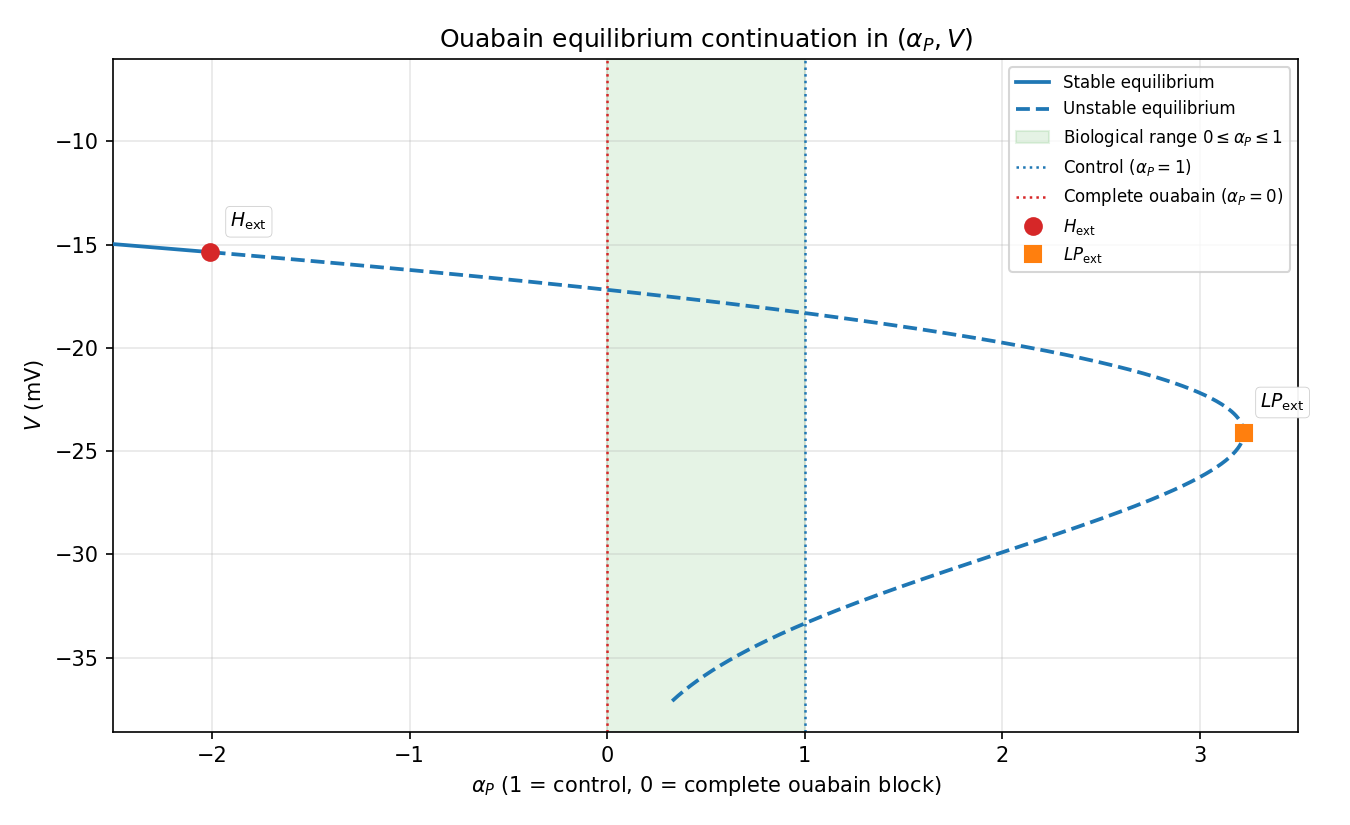


## 11. $\alpha_P$ limit-cycle continuation

LC-C is seeded from each **unique** Hopf on the $\alpha_P$ EP-C branch (biological or exterior). Exterior Hopfs are retained for mathematical cross-checking with the direct $I_{\mathrm{ep}}$ family under $\alpha_P = I_{\mathrm{ep}} / I_{\mathrm{ep}}^{(0)}$.


In [15]:
lc_aP_results = run_lc_from_hopfs(
    PC_aP, "EQ_alphaP", hopf_aP_seed_map, specials_aP, "alpha_P", name_prefix="LC_aP"
)
save_lc_csv(DATADIR / "alphaP_lcc_special_points.csv", lc_aP_results)

ok_aP = [k for k, info in lc_aP_results.items() if info.get("ok")]

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_aP,
    "alpha_P",
    specials_aP,
    title=r"$\alpha_P$ equilibria + LC envelopes (unique Hopfs)",
    xlabel=r"$\alpha_P$",
    shade_interval=(0.0, 1.0),
    shade_label=r"biological $[0,1]$",
    vlines=[
        (1.0, r"control $\alpha_P=1$", "C0"),
        (0.0, r"complete block $\alpha_P=0$", "C3"),
    ],
)
for i, h in enumerate(ok_aP):
    info = lc_aP_results[h]
    sol = info["sol"]
    a = np.asarray(sol["alpha_P"], dtype=float)
    col = lc_family_color(i)
    ax.plot(a, sol["V_max"], color=col, lw=2.0, label=rf"{h} $V_{{\max}}$", zorder=2)
    ax.plot(a, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{h} $V_{{\min}}$", zorder=2)
ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_alphaP_lcc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_alphaP_lcc.png")

if ok_aP:
    # Combined report + period plots when LC exists
    fig, ax = plt.subplots(figsize=(9, 5.5))
    plot_epc_report(
        ax,
        sol_aP,
        "alpha_P",
        specials_aP,
        title=r"$\alpha_P$ unique LC envelopes (report)",
        xlabel=r"$\alpha_P$",
        shade_interval=(0.0, 1.0),
        shade_label=r"biological $[0,1]$",
    )
    for i, h in enumerate(ok_aP):
        info = lc_aP_results[h]
        sol = info["sol"]
        a = np.asarray(sol["alpha_P"], dtype=float)
        col = lc_family_color(i)
        ax.plot(a, sol["V_max"], color=col, lw=2.0, label=rf"{h} $V_{{\max}}$", zorder=2)
        ax.plot(a, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{h} $V_{{\min}}$", zorder=2)
    ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_alphaP_lcc_report.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_alphaP_lcc_report.png")

    n_ok = len(ok_aP)
    fig, axes = plt.subplots(1, max(n_ok, 1), figsize=(6 * max(n_ok, 1), 4.5))
    if n_ok == 1:
        axes = [axes]
    for ax, key in zip(axes, ok_aP):
        sol = lc_aP_results[key]["sol"]
        a, _, _, period = lc_arrays(sol, "alpha_P")
        if period is None:
            continue
        ax.plot(a, period, lw=1.8)
        ax.set_xlabel(r"$\alpha_P$")
        ax.set_ylabel(r"period (ms)")
        ax.set_title(rf"{key} period")
        ax.grid(True, alpha=0.3)
        ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_alphaP_period.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_alphaP_period.png")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, key in enumerate(ok_aP):
        sol = lc_aP_results[key]["sol"]
        a, _, _, period = lc_arrays(sol, "alpha_P")
        if period is None:
            continue
        ax.semilogy(a, period, lw=1.6, color=lc_family_color(i), label=key)
    ax.set_xlabel(r"$\alpha_P$")
    ax.set_ylabel(r"period (ms, log)")
    ax.set_title(r"Limit-cycle period vs $\alpha_P$ (log)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which="both")
    ax.set_xlim(AP_PLOT_LO, AP_PLOT_HI)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_alphaP_period_log.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_alphaP_period_log.png")
else:
    print("No successful alpha_P LC-C branches.")



=== LC-C from EQ_alphaP:H1 as LC_aP_H_ext (H_ext) ===


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1     3  LP   2 -2.012477E+00  1.544732E+01 -1.536208E+01  9.145900E-01  6.851252E-01  5.225900E-01  1.000000E+00  9.424277E+01
   1   148  LP   3 -2.945661E+00  2.252034E+01  9.613701E+00  9.695701E-01  9.604464E-01  6.120716E-01  9.999969E-01  1.149148E+02
   1   200  EP   4 -2.476870E+00  2.724483E+01  1.765555E+01  9.739119E-01  9.797373E-01  6.356068E-01  9.997996E-01  1.297977E+02


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1     3  LP   2 -2.012477E+00  1.544732E+01 -1.536209E+01  9.145900E-01  6.851251E-01  5.225900E-01  1.000000E+00  9.424277E+01
   1   148  LP   3 -2.945661E+00  2.252034E+01  9.605980E+00  9.695729E-01  9.604457E-01  6.120534E-01  9.999969E-01  1.149148E+02
   1   200  EP   4 -2.476870E+00  2.724483E+01  1.767059E+01  9.739186E-01  9.798109E-01  6.355767E-01  9.997996E-01  1.297977E+02


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1     3  LP   2 -2.012477E+00  1.544732E+01 -1.536209E+01  9.145900E-01  6.851251E-01  5.225900E-01  1.000000E+00  9.424277E+01
   1   148  LP   3 -2.945661E+00  2.252034E+01  9.605980E+00  9.695729E-01  9.604457E-01  6.120534E-01  9.999969E-01  1.149148E+02
   1   200  EP   4 -2.476870E+00  2.724483E+01  1.767059E+01  9.739186E-01  9.798109E-01  6.355767E-01  9.997996E-01  1.297977E+02
  forward points: 200
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only.
LC-C finished in 1.694s; retained points: 200
LC validation H_ext: ok=True; amplitude near Hopf ~ 0 mV; period range [94.24, 129.8] ms
  specials (raw): ['LPC1', 'LPC2', 'LPC3', 'LPC4']
  specials (report LPC): ['LPC2']
  LPC caution: near-Hopf zero-amplitude LPCs omitted from report plots.

LC-C success summary:
  H_ext: ok=True dup_fwd_bwd=True err=None

saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_alphaP_lcc_report.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_alphaP_period.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_alphaP_period_log.png


**Figure — $\alpha_P$ LC envelopes (unique Hopfs).**

Limit-cycle envelopes from unique $\alpha_P$ Hopfs (biological or exterior). Exterior
branches are useful for $I_{\mathrm{ep}}\leftrightarrow\alpha_P$ cross-checking.

![$\alpha_P$ LC envelopes (unique Hopfs)](attachment:06_ouabain_alphaP_lcc.png)


**Figure — $\alpha_P$ unique LC envelopes (report).**

Report-quality overlay of unique LC $V_{\max}$ / $V_{\min}$ on the $\alpha_P$ equilibrium branch.

![$\alpha_P$ unique LC envelopes (report)](attachment:06_ouabain_alphaP_lcc_report.png)


**Figure — Limit-cycle period vs $\alpha_P$.**

Period $T$ (ms) for each successful unique $\alpha_P$ LC branch.

![Limit-cycle period vs $\alpha_P$](attachment:06_ouabain_alphaP_period.png)


**Figure — Limit-cycle period vs $\alpha_P$ (log scale).**

Shared log-$T$ axis for $\alpha_P$ LC periods. Time unit: **ms**.

![Limit-cycle period vs $\alpha_P$ (log scale)](attachment:06_ouabain_alphaP_period_log.png)


## 12. Cross-check: $I_{\mathrm{ep}}$ versus $\alpha_P$

If the parameterisations are equivalent, bifurcations should match under

$$
\alpha_P = I_{\mathrm{ep}} / I_{\mathrm{ep}}^{(0)}
$$

within continuation tolerance (`atol_alpha=0.05`, `atol_V=1.0`).

**STOP** and diagnose if matched unique specials disagree beyond tolerance before trusting LC-C / HTML.


In [16]:
def match_points_Iep_alphaP(iep_rows, ap_rows, kind, atol_alpha=0.05, atol_V=1.0):
    rows = []
    used = set()
    for gr in iep_rows:
        if gr["type"] != kind or "I_ep" not in gr:
            continue
        a_imp = gr["I_ep"] / I_EP0
        best = None
        best_score = 1e9
        for j, ar in enumerate(ap_rows):
            if j in used or ar["type"] != kind or "alpha_P" not in ar:
                continue
            score = abs(a_imp - ar["alpha_P"]) + 0.02 * abs(gr.get("V", 0) - ar.get("V", 0))
            if score < best_score:
                best_score = score
                best = (j, ar)
        if best is None:
            continue
        j, ar = best
        agree = abs(a_imp - ar["alpha_P"]) <= atol_alpha and abs(gr.get("V", 0) - ar.get("V", 0)) <= atol_V
        used.add(j)
        rows.append(
            {
                "Point": f"{kind}:{gr['label']}~{ar['label']}",
                "I_ep": gr["I_ep"],
                "implied_alpha_P": a_imp,
                "direct_alpha_P": ar["alpha_P"],
                "V_Iep": gr.get("V", float("nan")),
                "V_alpha": ar.get("V", float("nan")),
                "delta_alpha": a_imp - ar["alpha_P"],
                "delta_V": gr.get("V", float("nan")) - ar.get("V", float("nan")),
                "agreement": "yes" if agree else "check",
            }
        )
    return rows


atol_alpha = 0.05
atol_V = 1.0
cross = []
for kind in ("H", "LP"):
    cross.extend(match_points_Iep_alphaP(specials_Iep, specials_aP, kind, atol_alpha, atol_V))

print("I_ep vs alpha_P EP special-point cross-check:")
print(
    f"{'Point':28s} {'I_ep':>10s} {'imp_a':>8s} {'dir_a':>8s} {'V_I':>10s} {'V_a':>10s} {'agree':>7s}"
)
for r in cross:
    print(
        f"{r['Point']:28s} {r['I_ep']:10.4f} {r['implied_alpha_P']:8.4f} "
        f"{r['direct_alpha_P']:8.4f} {r['V_Iep']:10.4f} {r['V_alpha']:10.4f} {r['agreement']:>7s}"
    )

cross_ok = True
if not cross:
    print("No overlapping special-point matches found (check branch coverage).")
    if specials_Iep or specials_aP:
        print(
            "STOP: unique specials exist on one or both sides but no matches — "
            f"diagnose (atol_alpha={atol_alpha}, atol_V={atol_V})."
        )
        cross_ok = False
else:
    bad = [r for r in cross if r["agreement"] != "yes"]
    if bad:
        cross_ok = False
        print(
            "STOP: I_ep ↔ alpha_P special-point mismatch exceeds tolerance "
            f"(atol_alpha={atol_alpha}, atol_V={atol_V}). Diagnose before LC-C / HTML."
        )
        for r in bad:
            print("  BAD:", r)
    else:
        print("EP special-point cross-check: PASS")

save_special_csv(DATADIR / "Iep_alphaP_crosscheck.csv", cross)

# Optional LC cross-check if both sides have a successful LC.
# Folded LC branches are multi-valued in the free parameter, so naive
# 1D interp across a fold can spuriously disagree even when the families
# match. Compare: (1) global envelope extrema, (2) period ranges,
# (3) binned outer envelopes (min Vmin / max Vmax per I_ep bin).
print("\n=== LC cross-check under I_ep = alpha_P * I_EP0 ===")
lc_cross_rows = []
lc_cross_ok = False
info_I = next((v for v in lc_Iep_results.values() if v.get("ok")), None)
info_A = next((v for v in lc_aP_results.values() if v.get("ok")), None)

if not (info_I and info_A):
    print("SKIP: need at least one successful I_ep LC and one alpha_P LC.")
else:
    pI, vmin_I, vmax_I, TI = lc_arrays(info_I["sol"], "I_ep")
    pA, vmin_A, vmax_A, TA = lc_arrays(info_A["sol"], "alpha_P")
    I_from_A = I_EP0 * np.asarray(pA, dtype=float)

    lo = max(float(np.nanmin(pI)), float(np.nanmin(I_from_A)))
    hi = min(float(np.nanmax(pI)), float(np.nanmax(I_from_A)))
    print(f"Overlap I_ep interval: [{lo:.6f}, {hi:.6f}]")
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        print("FAIL: no overlapping parameter interval.")
    else:
        def outer_envelope(p, vmin, vmax, T, lo, hi, n_bins=40):
            p = np.asarray(p, dtype=float)
            vmin = np.asarray(vmin, dtype=float)
            vmax = np.asarray(vmax, dtype=float)
            T = np.asarray(T, dtype=float)
            edges = np.linspace(lo, hi, n_bins + 1)
            centres = 0.5 * (edges[:-1] + edges[1:])
            out_vmin = np.full(n_bins, np.nan)
            out_vmax = np.full(n_bins, np.nan)
            out_T = np.full(n_bins, np.nan)
            for i in range(n_bins):
                m = (p >= edges[i]) & (p <= edges[i + 1]) & np.isfinite(p)
                if not np.any(m):
                    continue
                out_vmin[i] = float(np.nanmin(vmin[m]))
                out_vmax[i] = float(np.nanmax(vmax[m]))
                out_T[i] = float(np.nanmedian(T[m]))
            return centres, out_vmin, out_vmax, out_T

        cI, vmin_Ie, vmax_Ie, T_Ie = outer_envelope(pI, vmin_I, vmax_I, TI, lo, hi)
        cA, vmin_Ae, vmax_Ae, T_Ae = outer_envelope(I_from_A, vmin_A, vmax_A, TA, lo, hi)
        both = np.isfinite(vmin_Ie) & np.isfinite(vmin_Ae)
        if not np.any(both):
            print("FAIL: no overlapping bins with data on both sides.")
            summary = {
                "overlap_Iep_lo": lo,
                "overlap_Iep_hi": hi,
                "max_abs_dVmin": float("nan"),
                "max_abs_dVmax": float("nan"),
                "max_abs_dT_ms": float("nan"),
                "d_global_Vmin": float("nan"),
                "d_global_Vmax": float("nan"),
                "d_period_min": float("nan"),
                "d_period_max": float("nan"),
                "method": "outer_envelope_bins",
            }
        else:
            d_vmin = np.abs(vmin_Ie[both] - vmin_Ae[both])
            d_vmax = np.abs(vmax_Ie[both] - vmax_Ae[both])
            d_T = np.abs(T_Ie[both] - T_Ae[both])
            d_g_vmin = abs(float(np.nanmin(vmin_I)) - float(np.nanmin(vmin_A)))
            d_g_vmax = abs(float(np.nanmax(vmax_I)) - float(np.nanmax(vmax_A)))
            d_Tmin = abs(float(np.nanmin(TI)) - float(np.nanmin(TA)))
            d_Tmax = abs(float(np.nanmax(TI)) - float(np.nanmax(TA)))
            summary = {
                "overlap_Iep_lo": lo,
                "overlap_Iep_hi": hi,
                "max_abs_dVmin": float(np.nanmax(d_vmin)),
                "max_abs_dVmax": float(np.nanmax(d_vmax)),
                "max_abs_dT_ms": float(np.nanmax(d_T)),
                "d_global_Vmin": d_g_vmin,
                "d_global_Vmax": d_g_vmax,
                "d_period_min": d_Tmin,
                "d_period_max": d_Tmax,
                "method": "outer_envelope_bins",
                "n_bins_compared": int(np.sum(both)),
            }
            print("LC outer-envelope / global errors on overlap:")
            for k, v in summary.items():
                if isinstance(v, float):
                    print(f"  {k}: {v:.6g}")
                else:
                    print(f"  {k}: {v}")
            # Tolerances: outer envelopes within a few mV; globals tighter;
            # periods within 5% of median (folded branches can differ slightly).
            med_T = float(np.nanmedian(TI))
            lc_cross_ok = (
                summary["max_abs_dVmin"] < 3.0
                and summary["max_abs_dVmax"] < 3.0
                and summary["d_global_Vmin"] < 1.0
                and summary["d_global_Vmax"] < 1.0
                and summary["d_period_min"] < max(5.0, 0.05 * med_T)
                and summary["d_period_max"] < max(5.0, 0.05 * med_T)
            )
            print(
                "LC cross-check:",
                "PASS" if lc_cross_ok else "FAIL — diagnose before trusting either LC branch",
            )
            print(
                "Note: naive 1D interp across an LPC fold is unreliable; "
                "this check uses binned outer envelopes + global extrema."
            )
        lc_cross_rows.append(
            {
                "label": "SUMMARY",
                "type": "SUMMARY",
                "agreement": "yes" if lc_cross_ok else "fail",
                **summary,
            }
        )

save_special_csv(DATADIR / "Iep_alphaP_lcc_crosscheck.csv", lc_cross_rows)
print("EP cross-check ok:", cross_ok, "| LC cross-ok:", lc_cross_ok)


I_ep vs alpha_P EP special-point cross-check:
Point                              I_ep    imp_a    dir_a        V_I        V_a   agree
H:H_ext~H_ext                    0.4427  -2.0125  -2.0125   -15.3636   -15.3636     yes
LP:LP_ext~LP_ext                -0.7091   3.2234   3.2234   -24.1126   -24.1126     yes
EP special-point cross-check: PASS
saved /notebooks/outputs/data/ouabain_bifurcation/Iep_alphaP_crosscheck.csv n= 2

=== LC cross-check under I_ep = alpha_P * I_EP0 ===
Overlap I_ep interval: [0.442745, 0.648045]
LC outer-envelope / global errors on overlap:
  overlap_Iep_lo: 0.442745
  overlap_Iep_hi: 0.648045
  max_abs_dVmin: 0.115559
  max_abs_dVmax: 0.164208
  max_abs_dT_ms: 13.1843
  d_global_Vmin: 0.0268116
  d_global_Vmax: 0.0370022
  d_period_min: 1.15448e-08
  d_period_max: 0.0984512
  method: outer_envelope_bins
  n_bins_compared: 40
LC cross-check: PASS
Note: naive 1D interp across an LPC fold is unreliable; this check uses binned outer envelopes + global extrema.
saved 

## 13. Ouabain-alone interpretation (link NB03 / NB04)

Time-domain anchors (do not replace continuation):

- NB03: complete ouabain ($I_{\mathrm{ep}}=0$) yields regular beating (ISI $\sim 0.45$ s).
- NB04: ouabain sweep $\alpha_P:1\to 0$ goes from bursting to regular beating; tangent-root *candidate* near $\alpha_P\approx 0.094$ (not a labelled fold until EP-C confirms).

**Continuation findings (this notebook):**

- Untreated-seeded EP-C finds **no** Hopf and **no** LP inside biological $\alpha_P\in[0,1]$ (equivalently $I_{\mathrm{ep}}\in[-0.22,0]$). The connected branch remains unstable through the biological interval.
- Unique exterior specials: Hopf at $I_{\mathrm{ep}}\approx 0.443$ ($\alpha_P\approx -2.01$) and LP at $I_{\mathrm{ep}}\approx -0.709$ ($\alpha_P\approx 3.22$). These are mathematical, not ouabain doses.
- Independent equilibrium root scan on $[0,1]$ recovers multiple roots near $\alpha_P\approx 0.1$ (consistent with the NB04 tangent-root candidate), but the untreated-seeded ContClass branch does not fold at a labelled LP inside $[0,1]$.
- Exterior Hopf LC-C yields a short-period orbit family (~94–130 ms) with an LPC fold; near-Hopf LPC markers are numerical caution items.

Bursting $\to$ beating along the ouabain path is therefore **not** mediated by a biological Hopf on this connected equilibrium branch. Time-domain evidence remains essential; do not infer SNIC/HOM from the exterior LP alone.

**Extended EP-C (hyperpolarized seed / larger step budget):** recovers the biological fold `LP_bio` near $\alpha_P\approx 0.094$, $V\approx -41.5$ mV (NB04 tangent candidate), plus exterior `H_ext,2` near $\alpha_P\approx 1.50$, $V\approx -50.1$ mV. See the dedicated section below. The untreated-seeded run above remains correct for the depolarized connected component; it simply did not complete the post-`LP_ext` lower sheet.


## 13a. Extended $\alpha_P$ equilibrium continuation (hyperpolarized sheet)

The untreated-seeded EP-C in §9 tracks the depolarized control equilibrium ($V^*\approx -18.3$ mV) and recovers only exterior `H_ext` / `LP_ext`. An independent root scan and the NB04 tangent localisation already indicated a hyperpolarized fold near $\alpha_P\approx 0.094$, $V^*\approx -41.5$ mV.

This section loads the **extended equilibrium-only** continuation produced by `scripts/run_06_ouabain_extended_epc.py` (hyperpolarized seed at $V^*\approx -47.4$ mV, with mid- and depolarized corroboration runs; increased `MaxNumPoints`). Limit-cycle / Hopf-bubble branches are intentionally omitted.

Outputs (new paths only; prior report figures are not overwritten):

- `outputs/data/ouabain_bifurcation/alphaP_extended_epc_special_points.csv`
- `ReportFigs/extended_ouabain/ouabain_alphaP_extended_equilibrium.png`


=== Extended alpha_P equilibrium special points ===
label      type    alpha_P       I_ep          V   interval        maxRe
H_ext,1    H     -2.012477   0.442745 -15.363601    outside    1.262e-10
H_ext,2    H      1.504077  -0.330897 -50.055650    outside    3.422e-12
LP_bio     LP     0.094119  -0.020706 -41.498959     inside       0.0012
LP_ext     LP     3.223372  -0.709142 -24.112585    outside      0.09157

Delta vs reference (alpha_P, V):
  LP_bio: d_alpha_P=+0.000019, d_V=+0.000041
  H_ext,1: d_alpha_P=+0.000023, d_V=+0.000399
  H_ext,2: d_alpha_P=-0.000023, d_V=+0.000350
  LP_ext: d_alpha_P=-0.000028, d_V=+0.000415
loaded /Users/calvinlai/Desktop/MATH3888/ReportFigs/extended_ouabain/ouabain_alphaP_extended_equilibrium.png


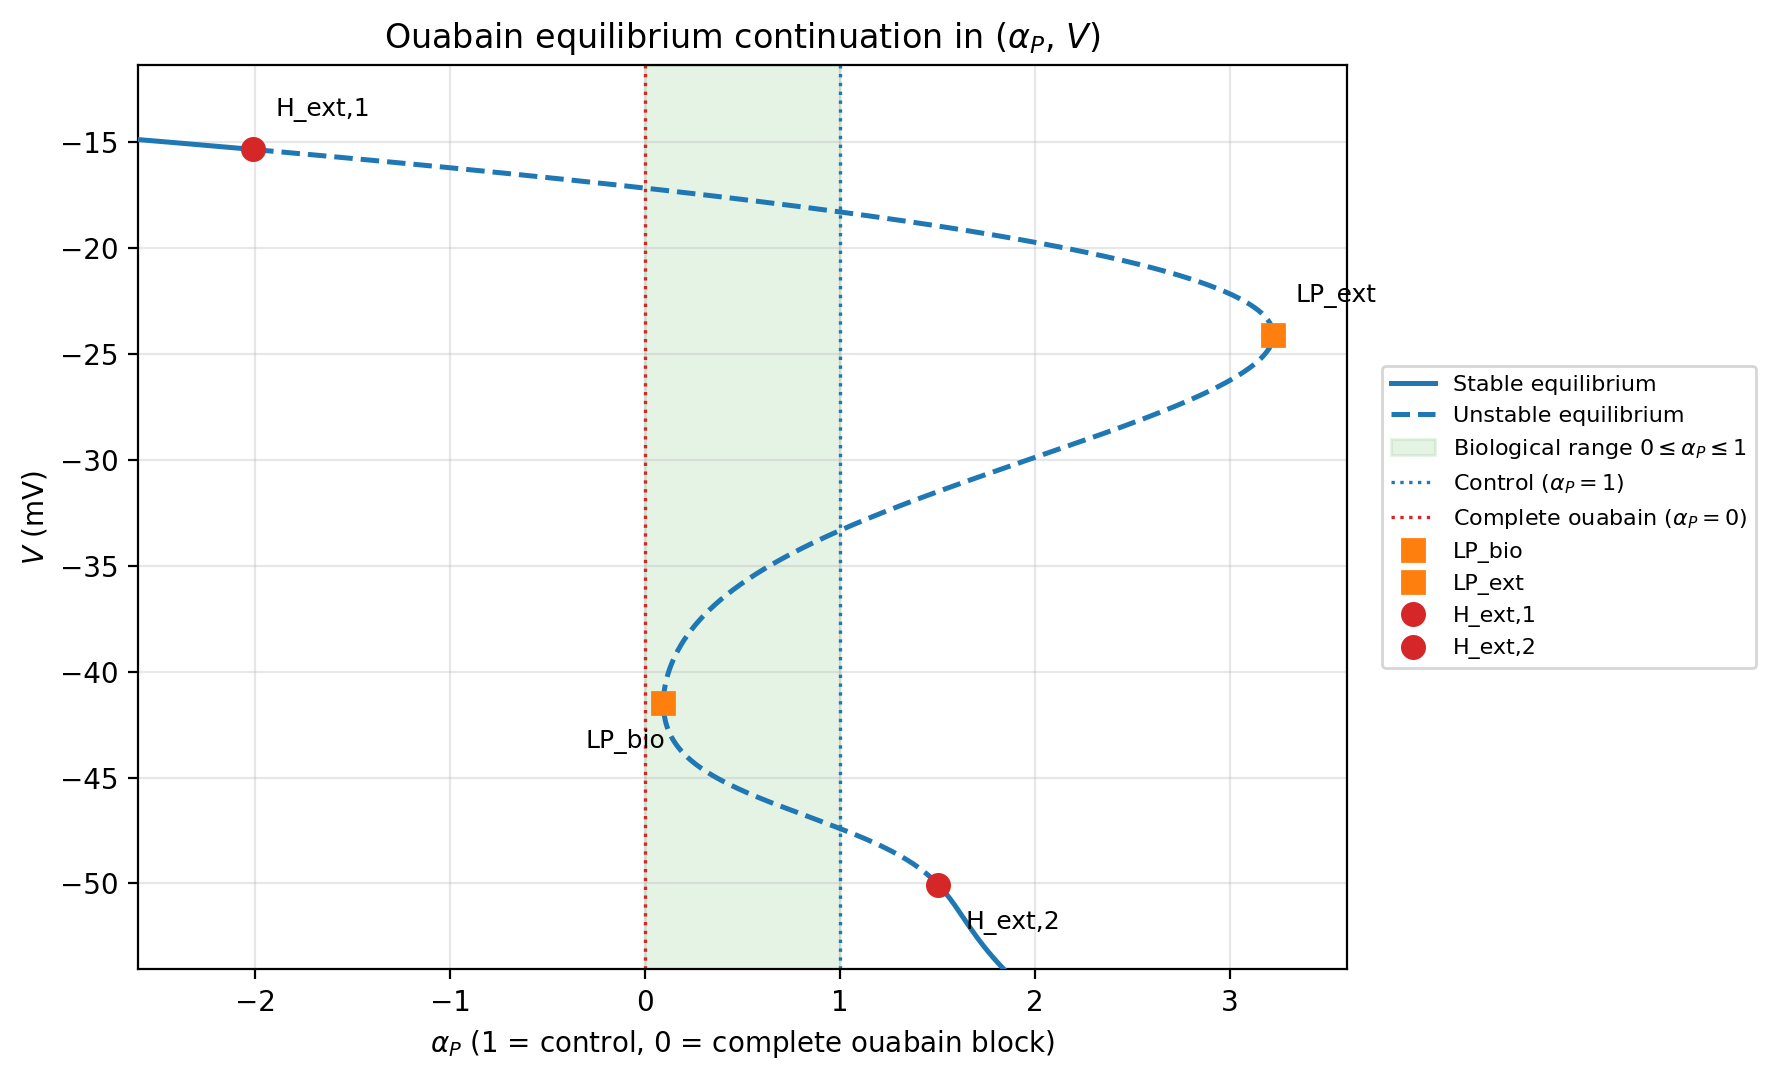

In [1]:
# Load extended EP-C specials (computed offline; do not overwrite prior CSVs).
import csv
from IPython.display import Image, display

EXT_DATA = DATADIR
EXT_FIG = REPO_ROOT / "ReportFigs" / "extended_ouabain" / "ouabain_alphaP_extended_equilibrium.png"
EXT_CSV = EXT_DATA / "alphaP_extended_epc_special_points.csv"

extended_specials = []
with open(EXT_CSV, newline="") as f:
    for row in csv.DictReader(f):
        extended_specials.append({
            "label": row["label"],
            "type": row["type"],
            "alpha_P": float(row["alpha_P"]),
            "I_ep": float(row["implied_I_ep"]),
            "V": float(row["V"]),
            "in_bio": row["in_biological_01"] == "True",
            "max_real_part_near": float(row.get("max_real_part_near") or "nan"),
        })

print("=== Extended alpha_P equilibrium special points ===")
print(f"{'label':10s} {'type':4s} {'alpha_P':>10s} {'I_ep':>10s} {'V':>10s} {'interval':>10s} {'maxRe':>12s}")
for r in sorted(extended_specials, key=lambda x: (x["type"], x["alpha_P"])):
    print(
        f"{r['label']:10s} {r['type']:4s} {r['alpha_P']:10.6f} {r['I_ep']:10.6f} "
        f"{r['V']:10.6f} {'inside' if r['in_bio'] else 'outside':>10s} "
        f"{r['max_real_part_near']:12.4g}"
    )

# Acceptance check vs NB04 / group-member reference (not hardcoded into continuation).
REF = {
    "LP_bio": (0.0941, -41.499),
    "H_ext,1": (-2.0125, -15.364),
    "H_ext,2": (1.5041, -50.056),
    "LP_ext": (3.2234, -24.113),
}
print("\nDelta vs reference (alpha_P, V):")
by_lab = {r["label"]: r for r in extended_specials}
for lab, (a_ref, V_ref) in REF.items():
    r = by_lab.get(lab)
    if r is None:
        print(f"  {lab}: MISSING")
    else:
        print(f"  {lab}: d_alpha_P={r['alpha_P']-a_ref:+.6f}, d_V={r['V']-V_ref:+.6f}")

assert EXT_FIG.is_file(), f"missing figure: {EXT_FIG}"
assert "LP_bio" in by_lab, "LP_bio not recovered in extended specials CSV"
display(Image(filename=str(EXT_FIG)))
print("loaded", EXT_FIG)


**Figure — Extended ouabain equilibrium continuation in $(\alpha_P, V)$.**

Equilibrium-only EP-C from a hyperpolarized control seed (corroborated by mid- and depolarized runs with a larger step budget). Solid / dashed blue: stable / unstable equilibria from stored $7$D eigenvalues. Orange squares: folds; red circles: Hopfs. Pale green: biological interval $0\leq\alpha_P\leq 1$. `LP_bio` ($\alpha_P\approx 0.094$, $V\approx -41.5$ mV) is the hyperpolarized fold missed by untreated-seeded EP-C; `H_ext,1`, `H_ext,2`, and `LP_ext` lie outside $[0,1]$. No limit-cycle envelopes are plotted. Saved to `ReportFigs/extended_ouabain/`.

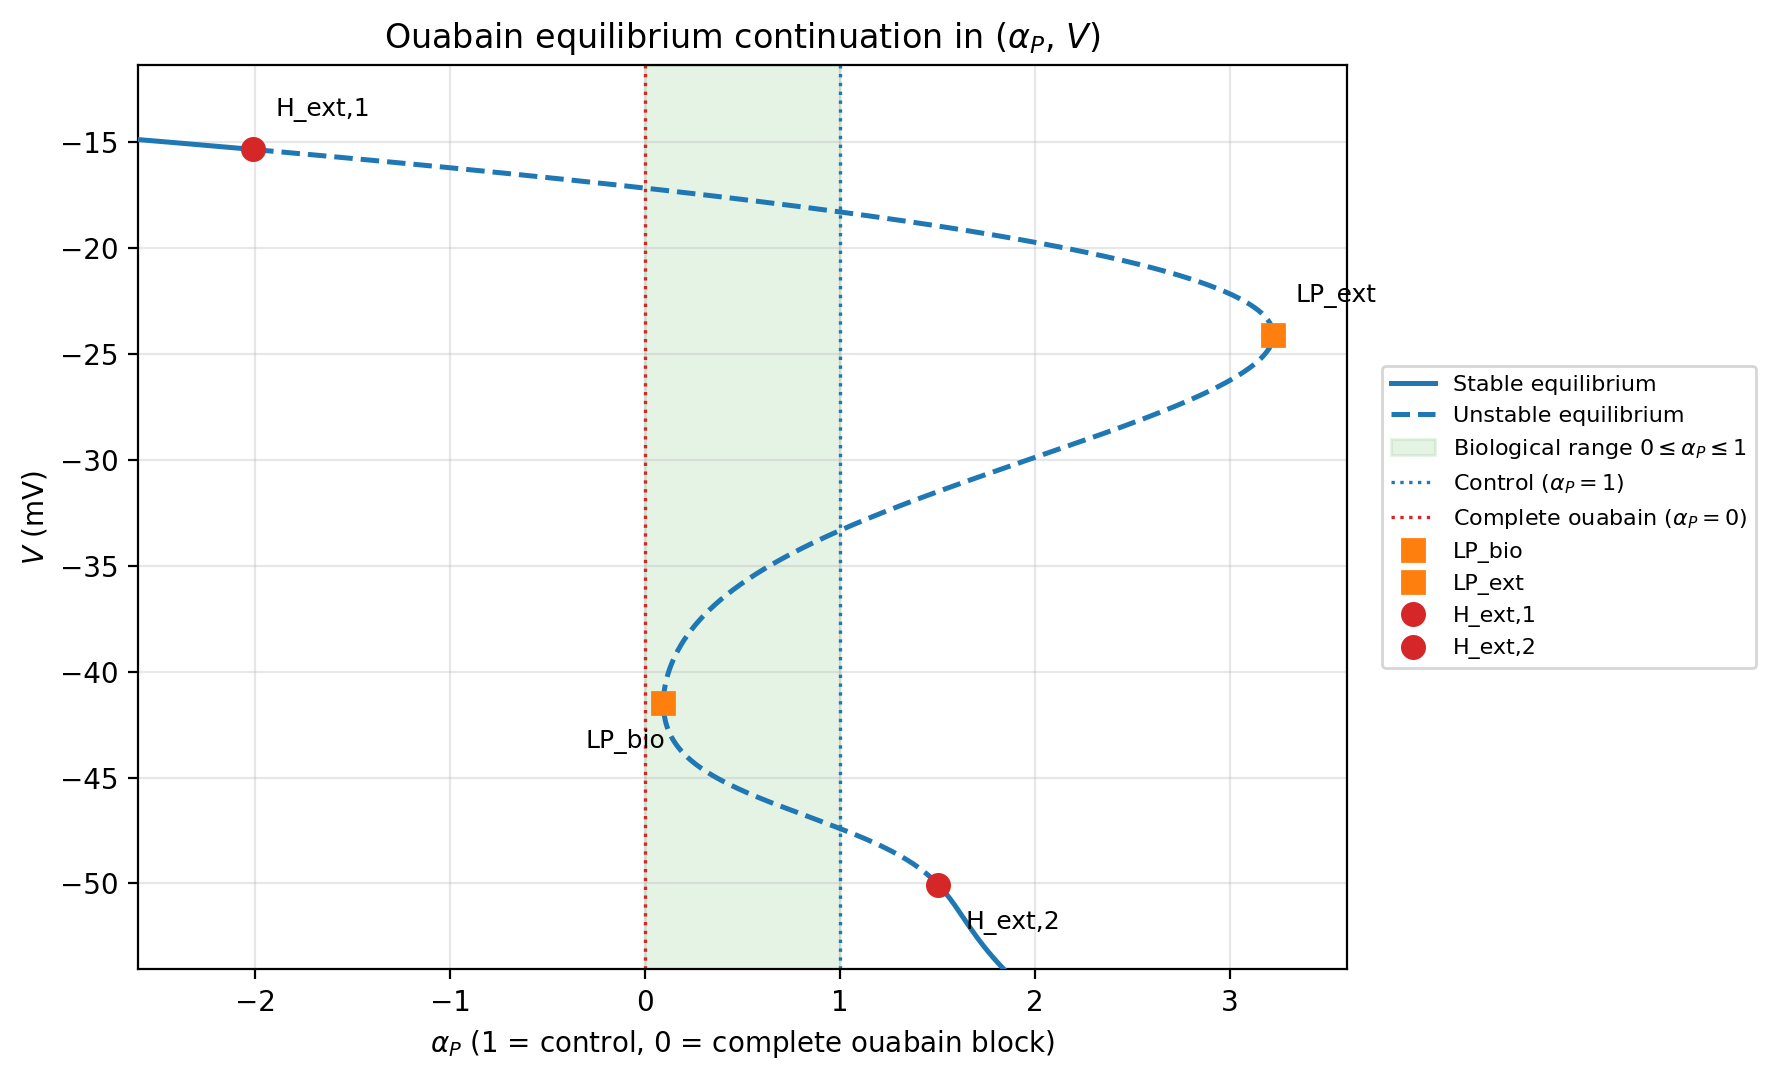


## 14. Complete-TTX model choice (checklist 3.6)

Primary continuation uses the **7D system with $g_I=0$** (equivalently $\alpha_I=0$). The exact 5D TTX reduction (`src/plant_kim_ttx_5d.py`) remains a **sanity check only** (validated in NB03); it is not a parallel full AUTO campaign here.

Seed from a complete-TTX equilibrium at $(\alpha_I,\alpha_P)=(0,1)$ — this may differ from the untreated $V^*\approx -18.3$ mV seed.


## 15. Ouabain under complete TTX ($\alpha_I=0$, freepar $\alpha_P$)


In [17]:
# Seed from TTX equilibrium scan (alpha_I=0, alpha_P=1); may differ from V*~-18.3.
pars_ttx = pars_from_alpha(0.0, 1.0)
roots_ttx = scan_equilibrium_voltages(pars_ttx)
print("Complete-TTX (alpha_I=0, alpha_P=1) current-balance roots:")
ttx_candidates = []
for r in roots_ttx:
    info = analyse_equilibrium(r["V_star"], pars_ttx, r["root_type"])
    print(
        f"  V*={info['V_star']:.6f} mV  {info['stability']}  "
        f"maxRe={info['max_real_part']:.6g}  accepted={info.get('accepted')}"
    )
    if info.get("accepted", True):
        ttx_candidates.append(info)

if not ttx_candidates:
    raise RuntimeError("No accepted equilibrium at alpha_I=0, alpha_P=1 for TTX+ouabain seed")

# Prefer a mid-range / slow-wave-relevant seed: choose the root with V* closest to -45 mV
# (TTX slow-wave envelope is roughly [-52,-39]); fall back to first accepted.
ttx_seed = min(ttx_candidates, key=lambda info: abs(float(info["V_star"]) + 45.0))
eq_ics_ttx = state_from_eq_info(ttx_seed)
print("\nComplete-TTX continuation seed:")
for k, v in eq_ics_ttx.items():
    print(f"  {k:4s} = {v:.6f}")
print(f"g_I = {pars_ttx['g_I']}, I_ep = {pars_ttx['I_ep']}")

# 7D with g_I=0 via build_alpha_P_vode_system(pars override)
pars_ttx_cont = dict(BASELINE_PARS)
pars_ttx_cont["g_I"] = 0.0
ode_ttx0 = build_alpha_P_vode_system(
    pars=pars_ttx_cont,
    ics=eq_ics_ttx,
    alpha_P=1.0,
    name="PlantKim_ttx0_alphaP_cont",
)
assert abs(float(ode_ttx0.pars["g_I"]) - 0.0) < 1e-15
PC_ttx0 = dst.ContClass(ode_ttx0)

init_ttx0 = dict(eq_ics_ttx)
init_ttx0["alpha_P"] = 1.0

PCt = dst.args(name="EQ_ttx0_alphaP", type="EP-C")
PCt.freepars = ["alpha_P"]
PCt.StepSize = 0.01
PCt.MinStepSize = 1e-6
PCt.MaxStepSize = 0.05
PCt.MaxNumPoints = 400
PCt.LocBifPoints = "all"
PCt.SaveEigen = True
PCt.verbosity = 0
PCt.initpoint = init_ttx0
PC_ttx0.newCurve(PCt)

print("Computing EQ_ttx0_alphaP forward...")
PC_ttx0["EQ_ttx0_alphaP"].forward()
print_specials(PC_ttx0["EQ_ttx0_alphaP"], " after forward")
print("Computing EQ_ttx0_alphaP backward...")
PC_ttx0["EQ_ttx0_alphaP"].backward()
print_specials(PC_ttx0["EQ_ttx0_alphaP"], " after backward")

sol_ttx0 = PC_ttx0["EQ_ttx0_alphaP"].sol
print("n points:", len(sol_ttx0["alpha_P"]))
print("alpha_P range:", float(np.min(sol_ttx0["alpha_P"])), float(np.max(sol_ttx0["alpha_P"])))
print("V range:", float(np.min(sol_ttx0["V"])), float(np.max(sol_ttx0["V"])))


Complete-TTX (alpha_I=0, alpha_P=1) current-balance roots:
  V*=-47.479594 mV  unstable  maxRe=0.000221889  accepted=True

Complete-TTX continuation seed:
  V    = -47.479594
  X_K  = 0.059842
  X_A  = 0.450570
  Y_A  = 0.336148
  X_P  = 0.416851
  X_I  = 0.025606
  Y_I  = 0.852267
g_I = 0.0, I_ep = -0.22


Computing EQ_ttx0_alphaP forward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after forward:
  H1: V=-44.7902, alpha_P=0.26792
Computing EQ_ttx0_alphaP backward...


Special points after backward:
  H1: V=-44.7902, alpha_P=0.26792
  H2: V=-49.9019, alpha_P=1.4803
n points: 800
alpha_P range: -1.7129947868954671 3.5732349256197815
V range: -66.95325127446671 -28.10023763046323


In [18]:
specials_ttx0_raw = collect_special_points(PC_ttx0["EQ_ttx0_alphaP"], kinds=("H", "LP", "B", "MX"))
specials_ttx0_unique = assign_physical_labels_alphaP(
    deduplicate_specials(specials_ttx0_raw, "alpha_P", atol_param=1e-4, atol_V=1e-2)
)
specials_ttx0 = [r for r in specials_ttx0_unique if r["type"] in ("H", "LP")]

ttx0_arr = np.asarray(sol_ttx0["alpha_P"], dtype=float)
for row in specials_ttx0 + specials_ttx0_raw:
    if "alpha_P" in row:
        row["implied_I_ep"] = row["alpha_P"] * I_EP0
        row["in_biological_01"] = bool(0.0 - 1e-8 <= row["alpha_P"] <= 1.0 + 1e-8)
        idx = int(np.argmin(np.abs(ttx0_arr - row["alpha_P"])))
        row["max_real_part_near"] = max_real_from_point_index(sol_ttx0, idx)

print("UNIQUE complete-TTX alpha_P specials:")
for row in specials_ttx0:
    print(
        f"  {row['label']:7s}  alpha_P={row.get('alpha_P', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f}  bio={row.get('in_biological_01')}  "
        f"raw={row.get('raw_labels')}"
    )

bio_H_ttx0 = [r for r in specials_ttx0 if r["type"] == "H" and r.get("in_biological_01")]
bio_LP_ttx0 = [r for r in specials_ttx0 if r["type"] == "LP" and r.get("in_biological_01")]
print(f"Inside biological [0,1]: H={len(bio_H_ttx0)}, LP={len(bio_LP_ttx0)}")

# --- Numerical stability pattern check (eigenvalue max Re, not visual only) ---
print("\n=== Complete-TTX equilibrium stability from stored eigenvalues ===")
a_ttx = np.asarray(sol_ttx0["alpha_P"], dtype=float)
mr_ttx = np.array([max_real_from_point_index(sol_ttx0, i) for i in range(len(a_ttx))], dtype=float)
order = np.argsort(a_ttx)
a_s, mr_s = a_ttx[order], mr_ttx[order]
finite = np.isfinite(mr_s)
a_s, mr_s = a_s[finite], mr_s[finite]
stab = mr_s < -1e-8
trans = np.where(np.diff(stab.astype(int)) != 0)[0]
print("Stability transitions along increasing alpha_P:")
for i in trans:
    print(
        f"  alpha_P≈{(a_s[i]+a_s[i+1])/2:.4f}: "
        f"{'stable' if stab[i] else 'unstable'} → {'stable' if stab[i+1] else 'unstable'} "
        f"(maxRe {mr_s[i]:.3e} → {mr_s[i+1]:.3e})"
    )

def _region_maxre(lo, hi):
    m = (a_s >= lo) & (a_s <= hi)
    if not np.any(m):
        return None
    return float(np.nanmedian(mr_s[m])), bool(np.nanmedian(mr_s[m]) < -1e-8)

h_bio_a = float(bio_H_ttx0[0]["alpha_P"]) if bio_H_ttx0 else 0.2679
h_ext_rows = [r for r in specials_ttx0 if r["type"] == "H" and not r.get("in_biological_01")]
h_ext_a = float(h_ext_rows[0]["alpha_P"]) if h_ext_rows else 1.4803
regions = {
    "left_of_H_bio": _region_maxre(0.0, h_bio_a - 0.05),
    "between_Hopfs": _region_maxre(h_bio_a + 0.05, h_ext_a - 0.05),
    "right_of_H_ext": _region_maxre(h_ext_a + 0.05, h_ext_a + 1.0),
    "at_control_alphaP1": _region_maxre(0.95, 1.05),
}
print("Region maxRe (median, stable?):")
for k, v in regions.items():
    print(f"  {k}: {v}")

pattern_ok = (
    regions["left_of_H_bio"] is not None
    and regions["between_Hopfs"] is not None
    and regions["right_of_H_ext"] is not None
    and regions["left_of_H_bio"][1] is True
    and regions["between_Hopfs"][1] is False
    and regions["right_of_H_ext"][1] is True
)
print(
    "stable→unstable→stable pattern confirmed:",
    "YES" if pattern_ok else "NO — STOP and diagnose before changing interpretation",
)
if not pattern_ok:
    raise RuntimeError("Complete-TTX eigenvalue stability pattern does not match expected S-U-S")

# Biological direction alpha_P: 1 -> 0
print("Biological path alpha_P 1→0 (sampled):")
for ap in [1.0, 0.5, 0.30, h_bio_a, 0.20, 0.0]:
    i = int(np.argmin(np.abs(a_s - ap)))
    print(
        f"  alpha_P≈{a_s[i]:.4f}: maxRe={mr_s[i]:.6e}  "
        f"{'stable' if stab[i] else 'unstable'}"
    )

save_special_csv(DATADIR / "ttx0_alphaP_epc_special_points_raw.csv", specials_ttx0_raw)
save_special_csv(DATADIR / "ttx0_alphaP_epc_special_points.csv", specials_ttx0)

hopf_ttx0_seed_map = map_hopf_seeds(
    specials_ttx0, specials_ttx0_raw, PC_ttx0["EQ_ttx0_alphaP"], "EQ_ttx0_alphaP", "alpha_P"
)

fig = plt.figure(figsize=(8, 5))
PC_ttx0.display(("alpha_P", "V"), stability=True, figure=fig.number)
plt.title(r"PyDSTool EP-C: complete-TTX ($g_I=0$) $\alpha_P$ continuation")
plt.xlabel(r"$\alpha_P$")
plt.ylabel(r"$V$ (mV)")
plt.xlim(-0.2, 3.0)
plt.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_epc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_epc.png")

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_ttx0,
    "alpha_P",
    specials_ttx0,
    title=r"Complete-TTX ouabain EP-C $(\alpha_P, V)$ — unique specials",
    xlabel=r"$\alpha_P$ ($g_I=0$; 1 = TTX-only, 0 = TTX+ouabain)",
    shade_interval=(0.0, 1.0),
    shade_label=r"biological $[0,1]$",
    vlines=[
        (1.0, r"TTX-only $\alpha_P=1$", "C0"),
        (0.0, r"TTX+ouabain $\alpha_P=0$", "C3"),
    ],
)
ax.set_xlim(-0.2, 3.0)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_epc_report.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_epc_report.png")


UNIQUE complete-TTX alpha_P specials:
  H_bio    alpha_P= 0.267920  V=-44.790173  bio=True  raw=['H1']
  H_ext    alpha_P= 1.480302  V=-49.901950  bio=False  raw=['H2']
Inside biological [0,1]: H=1, LP=0

=== Complete-TTX equilibrium stability from stored eigenvalues ===
Stability transitions along increasing alpha_P:
  alpha_P≈0.2631: stable → unstable (maxRe -5.649e-06 → -4.010e-12)
  alpha_P≈1.4831: unstable → stable (maxRe -4.064e-12 → -1.041e-05)
Region maxRe (median, stable?):
  left_of_H_bio: (-0.00014423194442484842, True)
  between_Hopfs: (0.00018510597445691395, False)
  right_of_H_ext: (-0.00013007905957881916, True)
  at_control_alphaP1: (0.00022188943635475053, False)
stable→unstable→stable pattern confirmed: YES
Biological path alpha_P 1→0 (sampled):
  alpha_P≈1.0000: maxRe=2.218894e-04  unstable
  alpha_P≈0.4976: maxRe=1.038549e-04  unstable
  alpha_P≈0.3008: maxRe=1.836336e-05  unstable
  alpha_P≈0.2679: maxRe=-4.010032e-12  unstable
  alpha_P≈0.1962: maxRe=-4.671438e-0

saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_ttx0_alphaP_epc_report.png


**Figure — Complete-TTX ($g_I=0$) $\alpha_P$ EP-C diagnostic.**

Raw PyCont continuation under complete TTX with freepar $\alpha_P$ (7D, $g_I=0$).

![Complete-TTX ($g_I=0$) $\alpha_P$ EP-C diagnostic](attachment:06_ouabain_ttx0_alphaP_epc.png)


**Figure — Complete-TTX ouabain EP-C (report).**

Unique specials on the complete-TTX slice $\alpha_I=0$, $\alpha_P:1\to 0$. Biological
$[0,1]$ shaded. Seed may differ from untreated $V^*\approx -18.3$ mV.

![Complete-TTX ouabain EP-C (report)](attachment:06_ouabain_ttx0_alphaP_epc_report.png)


### Complete-TTX equilibrium stability (eigenvalue check)

Using stored EP-C eigenvalues (`max Re`), the complete-TTX branch has a

**stable → unstable → stable**

pattern as $\alpha_P$ increases, with transitions at the two unique Hopfs:

- $H_{\mathrm{bio}}$ near $\alpha_P\approx 0.268$ (inside biological $[0,1]$);
- $H_{\mathrm{ext}}$ near $\alpha_P\approx 1.48$ (outside the biological interval).

The unstable segment lies **between** these Hopfs. Along the biological ouabain direction $\alpha_P:1\to 0$, the TTX-only equilibrium at $\alpha_P=1$ is unstable; after crossing $H_{\mathrm{bio}}$ the tracked equilibrium becomes **stable** for stronger pump inhibition ($\alpha_P\lesssim 0.27$).

This is **consistent with** Hypothesis 3 (pump inhibition under complete TTX eventually stabilising the equilibrium / suppressing the slow wave), but EP-C alone does **not** prove the full time-domain slow-wave $\to$ equilibrium transition — interpret together with NB03 combined-drug simulations and the LC family below.


In [19]:
# LC-C only if unique Hopf appears
lc_ttx0_results = run_lc_from_hopfs(
    PC_ttx0,
    "EQ_ttx0_alphaP",
    hopf_ttx0_seed_map,
    specials_ttx0,
    "alpha_P",
    name_prefix="LC_ttx0",
)

# If H_bio and H_ext seed the same Hopf-bubble family, retain one physical branch.
ok_ttx0_all = [k for k, info in lc_ttx0_results.items() if info.get("ok")]
if "H_bio" in ok_ttx0_all and "H_ext" in ok_ttx0_all:
    snap_bio = lc_arrays(lc_ttx0_results["H_bio"]["sol"], "alpha_P")
    snap_ext = lc_arrays(lc_ttx0_results["H_ext"]["sol"], "alpha_P")
    if branches_overlap(snap_bio, snap_ext):
        print(
            "Complete-TTX LC: H_bio and H_ext retrace the same orbit family "
            "(Hopf bubble) — retaining H_bio only for report plots."
        )
        lc_ttx0_results["H_ext"]["ok"] = False
        lc_ttx0_results["H_ext"]["direction_note"] = (
            lc_ttx0_results["H_ext"].get("direction_note", "")
            + ";duplicate_of_H_bio_family"
        )
        lc_ttx0_results["H_ext"]["duplicate_of"] = "H_bio"

save_lc_csv(DATADIR / "ttx0_alphaP_lcc_special_points.csv", lc_ttx0_results)

ok_ttx0 = [k for k, info in lc_ttx0_results.items() if info.get("ok")]

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_ttx0,
    "alpha_P",
    specials_ttx0,
    title=r"Complete-TTX $\alpha_P$ equilibria + LC (if any)",
    xlabel=r"$\alpha_P$",
    shade_interval=(0.0, 1.0),
    shade_label=r"biological $[0,1]$",
)
for i, h in enumerate(ok_ttx0):
    info = lc_ttx0_results[h]
    sol = info["sol"]
    a = np.asarray(sol["alpha_P"], dtype=float)
    col = lc_family_color(i)
    ax.plot(a, sol["V_max"], color=col, lw=2.0, label=rf"{h} $V_{{\max}}$", zorder=2)
    ax.plot(a, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{h} $V_{{\min}}$", zorder=2)
ax.set_xlim(-0.2, 3.0)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_lcc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_lcc.png")

if ok_ttx0:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    plot_epc_report(
        ax,
        sol_ttx0,
        "alpha_P",
        specials_ttx0,
        title=r"Complete-TTX unique LC envelopes (report)",
        xlabel=r"$\alpha_P$",
        shade_interval=(0.0, 1.0),
        shade_label=r"biological $[0,1]$",
    )
    for i, h in enumerate(ok_ttx0):
        info = lc_ttx0_results[h]
        sol = info["sol"]
        a = np.asarray(sol["alpha_P"], dtype=float)
        col = lc_family_color(i)
        ax.plot(a, sol["V_max"], color=col, lw=2.0, label=rf"{h} $V_{{\max}}$", zorder=2)
        ax.plot(a, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{h} $V_{{\min}}$", zorder=2)
    ax.set_xlim(-0.2, 3.0)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_lcc_report.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_lcc_report.png")

    n_ok = len(ok_ttx0)
    fig, axes = plt.subplots(1, max(n_ok, 1), figsize=(6 * max(n_ok, 1), 4.5))
    if n_ok == 1:
        axes = [axes]
    for ax, key in zip(axes, ok_ttx0):
        sol = lc_ttx0_results[key]["sol"]
        a, _, _, period = lc_arrays(sol, "alpha_P")
        if period is None:
            continue
        ax.plot(a, period, lw=1.8)
        ax.set_xlabel(r"$\alpha_P$")
        ax.set_ylabel(r"period (ms)")
        ax.set_title(rf"{key} period (TTX $g_I=0$)")
        ax.grid(True, alpha=0.3)
        ax.set_xlim(-0.2, 3.0)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_period.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_period.png")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, key in enumerate(ok_ttx0):
        sol = lc_ttx0_results[key]["sol"]
        a, _, _, period = lc_arrays(sol, "alpha_P")
        if period is None:
            continue
        ax.semilogy(a, period, lw=1.6, color=lc_family_color(i), label=key)
    ax.set_xlabel(r"$\alpha_P$")
    ax.set_ylabel(r"period (ms, log)")
    ax.set_title(r"Complete-TTX LC period vs $\alpha_P$ (log)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which="both")
    ax.set_xlim(-0.2, 3.0)
    fig.tight_layout()
    fig.savefig(FIGDIR / "06_ouabain_ttx0_alphaP_period_log.png", dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", FIGDIR / "06_ouabain_ttx0_alphaP_period_log.png")
else:
    print("No unique Hopf / no successful LC under complete TTX — EP-C + NB03 time domain only.")

print(
    "\nNote: exact 5D TTX reduction is a sanity check only "
    "(see src/plant_kim_ttx_5d.py / NB03); primary continuation remains 7D with g_I=0."
)



=== LC-C from EQ_ttx0_alphaP:H1 as LC_ttx0_H_bio (H_bio) ===


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   147  LP   2  1.480302E+00  4.991431E+01 -4.989916E+01  4.032521E-01  1.775981E-02  4.711618E-02  1.159927E-01  1.125797E+04
   1   200  EP   3  1.195444E+00  4.871716E+01 -3.989238E+01  6.007560E-01  7.599735E-02  1.200199E-01  4.923579E-01  1.160570E+04
 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    


   1   147  LP   2  1.480302E+00  4.991431E+01 -4.989900E+01  4.032551E-01  1.776024E-02  4.711693E-02  1.159952E-01  1.125797E+04
   1   200  EP   3  1.195455E+00  4.871724E+01 -3.988994E+01  6.007991E-01  7.603101E-02  1.200387E-01  4.923264E-01  1.160582E+04
 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    


   1   147  LP   2  1.480302E+00  4.991431E+01 -4.989900E+01  4.032551E-01  1.776024E-02  4.711693E-02  1.159952E-01  1.125797E+04
   1   200  EP   3  1.195455E+00  4.871724E+01 -3.988994E+01  6.007991E-01  7.603101E-02  1.200387E-01  4.923264E-01  1.160582E+04
  forward points: 200
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only.
LC-C finished in 1.705s; retained points: 200
LC validation H_bio: ok=True; amplitude near Hopf ~ 0 mV; period range [8325, 1.294e+04] ms
  specials (raw): ['LPC1', 'LPC2']
  specials (report LPC): ['LPC1']
  LPC caution: near-Hopf zero-amplitude LPCs omitted from report plots.

=== LC-C from EQ_ttx0_alphaP:H2 as LC_ttx0_H_ext (H_ext) ===
 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  8.290702E-01  4.615793E+01 -3.878083E+01  6.218637E-01  8.825172E-02  1.319289E-01  6.434447E-01  9.212877E+03


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  8.290708E-01  4.615793E+01 -3.878197E+01  6.218277E-01  8.823499E-02  1.319180E-01  6.434314E-01  9.212878E+03


 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  8.290708E-01  4.615793E+01 -3.878197E+01  6.218277E-01  8.823499E-02  1.319180E-01  6.434314E-01  9.212878E+03
  forward points: 200
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only.
LC-C finished in 1.670s; retained points: 200
LC validation H_ext: ok=True; amplitude near Hopf ~ 0 mV; period range [8325, 1.294e+04] ms
  specials (raw): (none)
  specials (report LPC): (none after filter)
  LPC caution: near-Hopf zero-amplitude LPCs omitted from report plots.

LC-C success summary:
  H_bio: ok=True dup_fwd_bwd=True err=None
  H_ext: ok=True dup_fwd_bwd=True err=None
Complete-TTX LC: H_bio and H_ext retrace the same orbit family (Hopf bubble) — retaining H_bio only for report plots.
saved /notebooks/outputs/data/ouabain_bifurcation/ttx0_alphaP_lcc_special_points.csv n= 4


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_ttx0_alphaP_lcc.png


saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_ttx0_alphaP_lcc_report.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_ttx0_alphaP_period.png
saved /notebooks/outputs/figures/ouabain_bifurcation/06_ouabain_ttx0_alphaP_period_log.png

Note: exact 5D TTX reduction is a sanity check only (see src/plant_kim_ttx_5d.py / NB03); primary continuation remains 7D with g_I=0.


**Figure — Complete-TTX $\alpha_P$ LC (if any).**

LC envelopes only if a unique Hopf appears under $g_I=0$. Otherwise EP-C + NB03 time
domain carry the interpretation.

![Complete-TTX $\alpha_P$ LC (if any)](attachment:06_ouabain_ttx0_alphaP_lcc.png)


**Figure — Complete-TTX unique LC envelopes (report).**

Report-quality LC overlay for the complete-TTX ouabain slice when AUTO succeeds.

![Complete-TTX unique LC envelopes (report)](attachment:06_ouabain_ttx0_alphaP_lcc_report.png)


**Figure — Complete-TTX LC period vs $\alpha_P$.**

Period $T$ (ms) for successful complete-TTX LC branches.

![Complete-TTX LC period vs $\alpha_P$](attachment:06_ouabain_ttx0_alphaP_period.png)


**Figure — Complete-TTX LC period vs $\alpha_P$ (log).**

Log-scale period comparison for complete-TTX LC branches. Time unit: **ms**.

![Complete-TTX LC period vs $\alpha_P$ (log)](attachment:06_ouabain_ttx0_alphaP_period_log.png)


In [20]:
# Cleaned report copy of the complete-TTX LC report figure: identical plotting calls,
# then title / legend / point labels only.
from src.report_figures import clean_dir, relabel_legend, retypeset_annotations

if ok_ttx0:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    plot_epc_report(
        ax,
        sol_ttx0,
        "alpha_P",
        specials_ttx0,
        title=r"Complete-TTX unique LC envelopes (report)",
        xlabel=r"$\alpha_P$",
        shade_interval=(0.0, 1.0),
        shade_label=r"biological $[0,1]$",
    )
    for i, h in enumerate(ok_ttx0):
        info = lc_ttx0_results[h]
        sol = info["sol"]
        a = np.asarray(sol["alpha_P"], dtype=float)
        col = lc_family_color(i)
        ax.plot(a, sol["V_max"], color=col, lw=2.0, label=rf"{h} $V_{{\max}}$", zorder=2)
        ax.plot(a, sol["V_min"], color=col, lw=2.0, ls="--", label=rf"{h} $V_{{\min}}$", zorder=2)
    ax.set_xlim(-0.2, 3.0)
    # Layout is computed with the original text so the axes box matches the original figure exactly.
    fig.tight_layout()

    assert ok_ttx0 == ["H_bio"], ok_ttx0
    ax.set_title("Ouabain continuation under complete TTX")
    relabel_legend(
        ax,
        {
            "stable (max Re < 0)": "Stable equilibrium",
            "unstable (max Re >= 0)": "Unstable equilibrium",
            "H_bio": r"$H_{\mathrm{bio}}$",
            "H_ext": r"$H_{\mathrm{ext}}$",
            r"biological $[0,1]$": r"Biological range $0\leq\alpha_P\leq1$",
            r"H_bio $V_{\max}$": r"Limit-cycle $V_{\max}$",
            r"H_bio $V_{\min}$": r"Limit-cycle $V_{\min}$",
        },
    )
    retypeset_annotations(ax, {"H_bio": r"$H_{\mathrm{bio}}$", "H_ext": r"$H_{\mathrm{ext}}$"})
    clean_path = clean_dir() / "ouabain_complete_ttx_continuation.png"
    fig.savefig(clean_path, dpi=150)
    plt.show()
    plt.close(fig)
    print("saved", clean_path)
else:
    print("No successful complete-TTX LC branch; cleaned LC report figure not produced.")

saved /notebooks/ReportFigs/cleaned/ouabain_complete_ttx_continuation.png


**Cleaned report figure — ouabain continuation under complete TTX.**

Report copy of the complete-TTX ($\alpha_I=0$) LC report figure above: identical equilibrium
branch, Hopf points ($H_{\mathrm{bio}}$ at $\alpha_P\approx 0.268$, $H_{\mathrm{ext}}$ at
$\alpha_P\approx 1.48$), AUTO limit-cycle $V_{\max}$/$V_{\min}$ envelope, shading and limits; only
title, legend and point labels are typeset. Saved to `ReportFigs/cleaned/`.

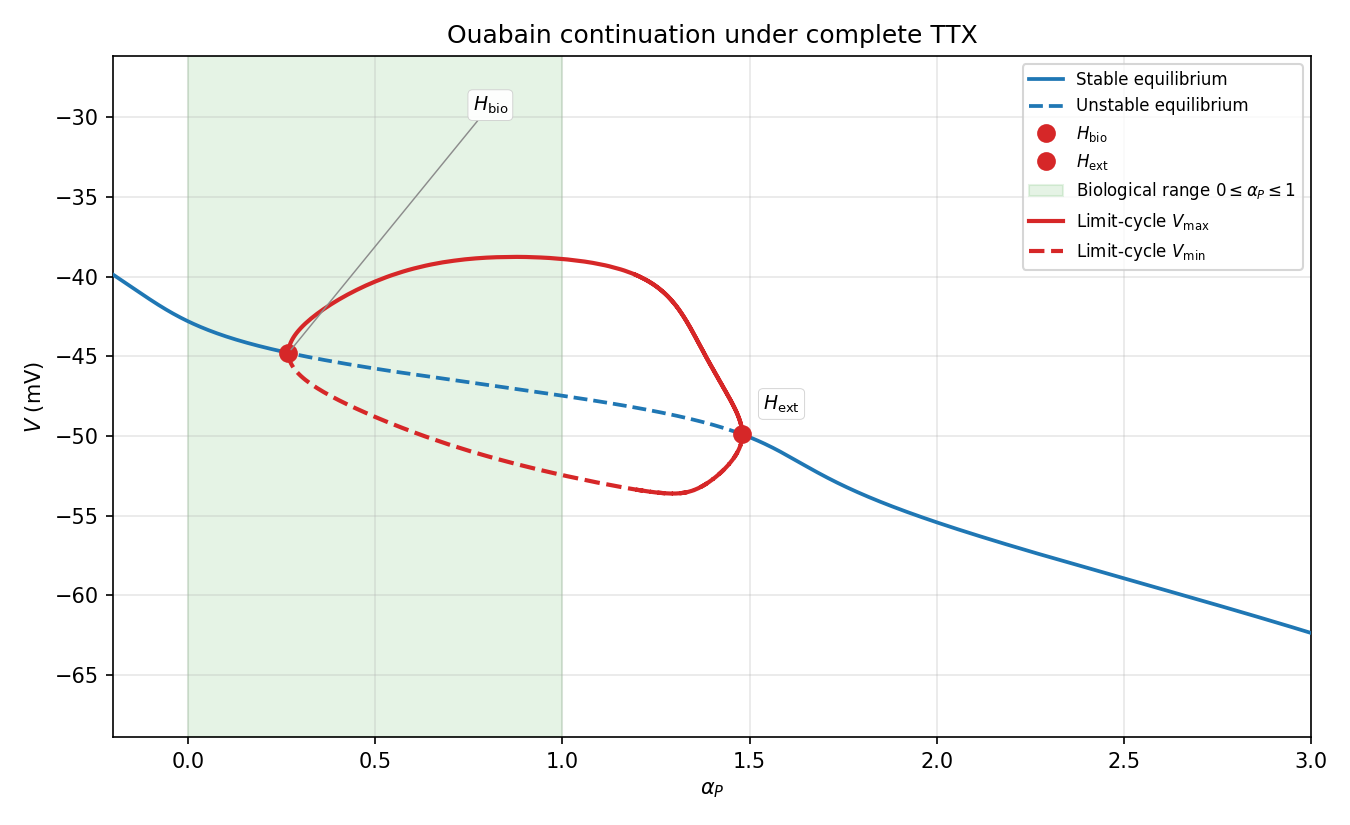


## 16. Three-setting comparison

| Setting | Parameters | Time-domain (NB03/04) | Bifurcation landmarks (this notebook) |
|---|---|---|---|
| Control / untreated | $\alpha_I=\alpha_P=1$ | Normal bursting | Seed $V^*\approx -18.3$ (unstable) |
| Ouabain alone | $\alpha_I=1$, $\alpha_P:1\to 0$ | Bursting → regular beating | **No** bio H/LP on connected EP-C; exterior H/LP only; multi-root scan near $\alpha_P\approx 0.1$ |
| TTX + ouabain | $\alpha_I=0$, $\alpha_P:1\to 0$ | Slow wave → equilibrium | Biological Hopf $H_{\mathrm{bio}}$ at $\alpha_P\approx 0.268$; exterior $H_{\mathrm{ext}}$ at $\approx 1.48$; eigenvalue-confirmed stable–unstable–stable; one LC Hopf-bubble family |

Under complete TTX, the tracked equilibrium is unstable at $\alpha_P=1$ and becomes stable for $\alpha_P\lesssim 0.27$ after crossing $H_{\mathrm{bio}}$ — **consistent with** the combined-drug time-domain endpoint, but not a sole proof of Hypothesis 3.


In [21]:
print("=== Three-setting numerical snapshot ===")
print("Control seed V* ≈", float(eq_ics["V"]))
print(f"Ouabain-alone unique specials: H={sum(1 for r in specials_aP if r['type']=='H')}, "
      f"LP={sum(1 for r in specials_aP if r['type']=='LP')}; "
      f"bio H={len(bio_H_aP)}, bio LP={len(bio_LP_aP)}")
print(f"Complete-TTX unique specials: H={sum(1 for r in specials_ttx0 if r['type']=='H')}, "
      f"LP={sum(1 for r in specials_ttx0 if r['type']=='LP')}; "
      f"bio H={len(bio_H_ttx0)}, bio LP={len(bio_LP_ttx0)}")
print(f"I_ep unique specials: H={n_H}, LP={n_LP}")
print("Successful LC branches: I_ep=", sum(1 for v in lc_Iep_results.values() if v.get('ok')),
      " alpha_P=", sum(1 for v in lc_aP_results.values() if v.get('ok')),
      " ttx0=", sum(1 for v in lc_ttx0_results.values() if v.get('ok')))


=== Three-setting numerical snapshot ===
Control seed V* ≈ -18.3115530973215
Ouabain-alone unique specials: H=1, LP=1; bio H=0, bio LP=0
Complete-TTX unique specials: H=2, LP=0; bio H=1, bio LP=0
I_ep unique specials: H=1, LP=1
Successful LC branches: I_ep= 1  alpha_P= 1  ttx0= 1


## 17. Numerical limitations / cautions

- Model time is **milliseconds**; AUTO `_T` is labelled in ms.
- $I_{\mathrm{ep}}$ continuation is intentionally bounded (~$[-1,1]$); values outside $[-0.22,0]$ are non-physical for ouabain.
- Because $I_{\mathrm{ep}}^{(0)}<0$, reducing pump **magnitude** toward zero maps $\alpha_P:1\to 0$ onto $I_{\mathrm{ep}}:-0.22\to 0$.
- PyCont may leave `stab` unset; stability plots use $\max\mathrm{Re}(\lambda)$ when available.
- AUTO `LC-C` requires Docker; artefacts are written to the process CWD.
- `MX` means numerical termination, not a named bifurcation.
- Large periods near termination are suggestive only — not HOM/SNIC proofs.
- Near-Hopf LPC markers are often coincident zero-amplitude artefacts — soft-pedal biological claims.
- Raw special-point labels (`H1`, `LP1`, …) are software ordering; report labels use `H_bio` / `H_ext` / `LP_bio` / `LP_ext`.
- Native PyDSTool LC `display` overlays can be blank/sparse; report figures use extracted $V_{\min}$/$V_{\max}$.
- Bursting orbits can make AUTO LC-C harder than TTX slow-wave; if LC fails, retain EP-C + NB03/04 time domain.
- Do **not** assume a fixed Hopf/LP count from TTX Notebook 05.


## 18. Summary and saved outputs


In [22]:
print("=== Summary ===")
print(f"I_ep EP-C RAW: H={n_H_raw}, LP={n_LP_raw}")
print(f"I_ep EP-C UNIQUE: H={n_H}, LP={n_LP}")
for row in specials_Iep:
    print(
        f"  {row['label']}: I_ep={row['I_ep']:.6f}, alpha_P~={row['I_ep']/I_EP0:.6f}, "
        f"V={row['V']:.6f}, raw={row.get('raw_labels')}"
    )
print("I_ep LC-C (unique seeds):")
for h, info in lc_Iep_results.items():
    meta = info.get("meta") or {}
    print(
        f"  {h}: ok={info['ok']} dup_fwd_bwd={info.get('forward_backward_duplicate')} "
        f"T∈[{meta.get('period_min', float('nan')):.4g}, {meta.get('period_max', float('nan')):.4g}] ms "
        f"err={info['error']}"
    )
print(f"alpha_P EP-C unique: {len(specials_aP)}; bio H={len(bio_H_aP)}, bio LP={len(bio_LP_aP)}")
print("alpha_P LC-C:")
if not lc_aP_results:
    print("  (none)")
for h, info in lc_aP_results.items():
    print(
        f"  {h}: ok={info['ok']} dup_fwd_bwd={info.get('forward_backward_duplicate')} err={info['error']}"
    )
print(f"ttx0 alpha_P EP-C unique: {len(specials_ttx0)}; bio H={len(bio_H_ttx0)}, bio LP={len(bio_LP_ttx0)}")
print("ttx0 LC-C:")
if not lc_ttx0_results:
    print("  (none)")
for h, info in lc_ttx0_results.items():
    print(f"  {h}: ok={info['ok']} err={info['error']}")
print("EP I_ep↔alpha_P cross-check:", "PASS" if cross_ok else "FAIL/STOP")
print("LC I_ep↔alpha_P cross-check:", "PASS" if lc_cross_ok else "FAIL/SKIP")

print("\nFigures in", FIGDIR)
for p in sorted(FIGDIR.glob("06_ouabain_*")):
    print(" ", p.name, p.stat().st_size, "bytes")
print("Data in", DATADIR)
for p in sorted(DATADIR.glob("*.csv")):
    print(" ", p.name)
print("\nNotebook 06 ouabain bifurcation analysis complete.")

# Extended equilibrium-only outputs (do not overwrite prior report figs)
ext_csv = DATADIR / "alphaP_extended_epc_special_points.csv"
ext_fig = REPO_ROOT / "ReportFigs" / "extended_ouabain" / "ouabain_alphaP_extended_equilibrium.png"
print("Extended alpha_P EP-C CSV exists:", ext_csv.is_file(), "->", ext_csv)
print("Extended alpha_P EP-C figure exists:", ext_fig.is_file(), "->", ext_fig)


=== Summary ===
I_ep EP-C RAW: H=1, LP=1
I_ep EP-C UNIQUE: H=1, LP=1
  H_ext: I_ep=0.442745, alpha_P~=-2.012477, V=-15.363601, raw=['H1']
  LP_ext: I_ep=-0.709142, alpha_P~=3.223372, V=-24.112584, raw=['LP1']
I_ep LC-C (unique seeds):
  H_ext: ok=True dup_fwd_bwd=True T∈[94.24, 129.9] ms err=None
alpha_P EP-C unique: 2; bio H=0, bio LP=0
alpha_P LC-C:
  H_ext: ok=True dup_fwd_bwd=True err=None
ttx0 alpha_P EP-C unique: 2; bio H=1, bio LP=0
ttx0 LC-C:
  H_bio: ok=True err=None
  H_ext: ok=False err=None
EP I_ep↔alpha_P cross-check: PASS
LC I_ep↔alpha_P cross-check: PASS

Figures in /notebooks/outputs/figures/ouabain_bifurcation
  06_ouabain_Iep_epc.png 40627 bytes
  06_ouabain_Iep_epc_report.png 80087 bytes
  06_ouabain_Iep_lcc.png 67272 bytes
  06_ouabain_Iep_lcc_report.png 60321 bytes
  06_ouabain_Iep_period.png 33555 bytes
  06_ouabain_Iep_period_log.png 48366 bytes
  06_ouabain_alphaP_epc.png 40032 bytes
  06_ouabain_alphaP_epc_report.png 81299 bytes
  06_ouabain_alphaP_lcc.png 8100